# Consistency Models：实验设计与论文结论验证

建议使用 **二维高斯混合分布（2D Gaussian Mixture）+ PyTorch**，设计一套从数学性质到实际生成效果的验证实验。

不必一开始就训练 CIFAR-10。二维实验的优势是：我们可以计算真实 Score、构造准确的 Probability Flow ODE、可视化概率流轨迹，并直接测量 Consistency Model 的终点预测误差。

这样不仅能观察模型是否生成成功，还能验证**为什么 CD 和 CT 能够学习一致性映射，以及它们在哪些条件下存在差异**。

## 一、实验总体设计

我建议做六组实验，分别对应论文的六个重要结论。

| 实验 | 验证结论 | 核心观测指标 |
|---|---|---|
| 1. PF ODE 与一致性函数 | 同一条 ODE 轨迹上的状态具有相同终点 | 轨迹可视化、一致性误差 |
| 2. Consistency Distillation | CD 能够学习教师 ODE 的终点映射 | 终点 MSE、生成分布 |
| 3. Consistency Training | CT 不需要教师 Score，也能学习终点映射 | 终点 MSE、生成分布 |
| 4. CD 与 CT 的渐近关系 | 时间间隔缩小时，两种训练目标渐近接近 | Loss 差值与时间间隔 |
| 5. 一步与多步采样 | 一步可以生成，多步可能改善质量 | MMD、NFE、采样时间 |
| 6. Euler 与 Heun | 教师 Solver 的阶数影响 CD 的逼近精度 | Log-Log 误差曲线 |

其中最重要的是实验 3、4、6，因为它们能够验证论文背后的数学原理，而不仅是复现生成效果。

---

## 二、统一实验环境

### 2.1 数据分布

使用二维八模态高斯混合分布：

$$
p_{\mathrm{data}}(x)
=
\frac18\sum_{k=1}^{8}
\mathcal N(x;\mu_k,\sigma_{\mathrm{data}}^2I)
\tag{1}
$$

八个中心均匀分布在圆周上：

$$
\mu_k=
r
\begin{bmatrix}
\cos(2\pi k/8)\\
\sin(2\pi k/8)
\end{bmatrix}
\tag{2}
$$

取：

$$
r=4,\qquad \sigma_{\mathrm{data}}=0.3
$$

这样数据分布具有明显的多模态结构，容易观察生成模型是否出现模式丢失。

### 2.2 前向加噪

按照论文 EDM/VE 参数化：

$$
X_t=X_0+tZ
\tag{3}
$$

其中：

$$
Z\sim\mathcal N(0,I)
$$

时间范围：

$$
t\in[\epsilon,T]
$$

建议：

$$
\epsilon=0.01,\qquad T=10
$$

### 2.3 解析 Score

这是本实验最重要的设计。

由于原始分布是 GMM，加噪后的边缘分布仍然是 GMM：

$$
p_t(x)
=
\frac18\sum_{k=1}^{8}
\mathcal N(x;\mu_k,(\sigma_{\mathrm{data}}^2+t^2)I)
\tag{4}
$$

定义每个高斯分量的后验责任：

$$
w_k(x,t)
=
\frac{
\mathcal N(x;\mu_k,(\sigma_{\mathrm{data}}^2+t^2)I)
}{
\sum_j
\mathcal N(x;\mu_j,(\sigma_{\mathrm{data}}^2+t^2)I)
}
\tag{5}
$$

于是：

$$
\boxed{
\nabla_x\log p_t(x)
=
\sum_{k=1}^{8}
w_k(x,t)
\frac{\mu_k-x}{\sigma_{\mathrm{data}}^2+t^2}
}
\tag{6}
$$

因此 PF ODE 的真实速度场为：

$$
\boxed{
v^*(x,t)
=
-t\sum_{k=1}^{8}
w_k(x,t)
\frac{\mu_k-x}{\sigma_{\mathrm{data}}^2+t^2}
}
\tag{7}
$$

这意味着：

**我们不需要训练 Score Network，就能够获得准确的教师速度场。**

后续可以将高精度数值积分得到的终点作为 Ground Truth，避免把 Score 网络误差与 Consistency Model 的误差混在一起。

### 2.4 统一网络结构

使用简单的时间条件 MLP：

$$
F_\theta:\mathbb R^2\times\mathbb R\rightarrow\mathbb R^2
$$

输入：

$$
[x_1,x_2,\log t]
$$

隐藏层：

$$
3\rightarrow128\rightarrow128\rightarrow128\rightarrow2
$$

激活函数使用 SiLU。

Consistency Model 使用：

$$
f_\theta(x,t)
=
c_{\mathrm{skip}}(t)x+
c_{\mathrm{out}}(t)F_\theta(x,t)
\tag{8}
$$

其中可选择：

$$
c_{\mathrm{skip}}(t)=\frac{\sigma_{\mathrm{data}}^2}{(t-\epsilon)^2+\sigma_{\mathrm{data}}^2}
$$

$$
c_{\mathrm{out}}(t)=
\frac{\sigma_{\mathrm{data}}(t-\epsilon)}
{\sqrt{\sigma_{\mathrm{data}}^2+(t-\epsilon)^2}}
$$

从而保证：

$$
f_\theta(x,\epsilon)=x
$$

这里使用的是适合本实验的 EDM 风格预条件化，重点是保证边界条件，而非逐项复刻论文图像网络。

实现时必须区分两个尺度：$\sigma_{\mathrm{component}}=0.3$ 描述单个模态宽度，而预条件化中的 $\sigma_{\mathrm{model}}$ 应反映整个八模态数据的总体坐标尺度。本实验取

$$
\sigma_{\mathrm{model}}=\sqrt{r^2/2+\sigma_{\mathrm{component}}^2}pprox2.84,
$$

并使用 $c_{\mathrm{in}}(t)=1/\sqrt{t^2+\sigma_{\mathrm{model}}^2}$ 归一化网络输入。

---


In [1]:
import os
import copy
import math
import time
import random
from dataclasses import dataclass
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display


@dataclass
class Config:
    seed: int = 42

    # GMM
    num_modes: int = 8
    radius: float = 4.0
    data_std: float = 0.3       # within-component standard deviation
    model_data_std: float = math.sqrt(4.0**2 / 2.0 + 0.3**2)  # global per-coordinate scale

    # VE diffusion
    eps: float = 0.01
    T: float = 10.0

    # Model
    hidden_dim: int = 128
    num_hidden_layers: int = 3

    # Training
    batch_size: int = 512
    train_steps: int = 10000
    lr: float = 1e-3
    ema_decay: float = 0.99

    # Time discretization
    num_time_steps: int = 100
    schedule_start: int = 10
    schedule_end: int = 200
    time_grid_rho: float = 7.0

    # Evaluation
    eval_samples: int = 2048
    eval_batch_size: int = 512
    reference_steps: int = 1000

    # Ablation
    ablation_steps: int = 4000
    run_ablations: bool = True

    # Output
    output_dir: str = "results"

    # Reproducibility
    deterministic: bool = False


CFG = Config()

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    if CFG.deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def setup():
    set_seed(CFG.seed)
    print("=" * 70)
    print("Consistency Models - 2D Experiments")
    print("=" * 70)
    print(f"Device: {DEVICE}")
    print(f"Training steps: {CFG.train_steps}")
    print(f"Batch size: {CFG.batch_size}")
    print(f"Model data scale: {CFG.model_data_std:.4f}")
    print("Results: embedded in this notebook")
    print("=" * 70)


def save_figure(name: str):
    """Render the current figure inline; name is kept as a readable experiment label."""
    plt.show()
    plt.close()


def save_csv(data, name: str):
    """Display result tables inline so the notebook remains a single-file artifact."""
    print(name)
    display(pd.DataFrame(data))


def to_numpy(x: torch.Tensor):
    return x.detach().cpu().numpy()

setup()


Consistency Models - 2D Experiments
Device: cuda
Training steps: 10000
Batch size: 512
Model data scale: 2.8443
Results: embedded in this notebook


## 数据分布与解析速度场

下面实现八模态 GMM、任意噪声时刻的精确边缘采样、解析 Score 和 PF ODE 速度。先直接查看干净数据以及两个噪声时刻的边缘分布，确认后续教师场对应的概率路径。


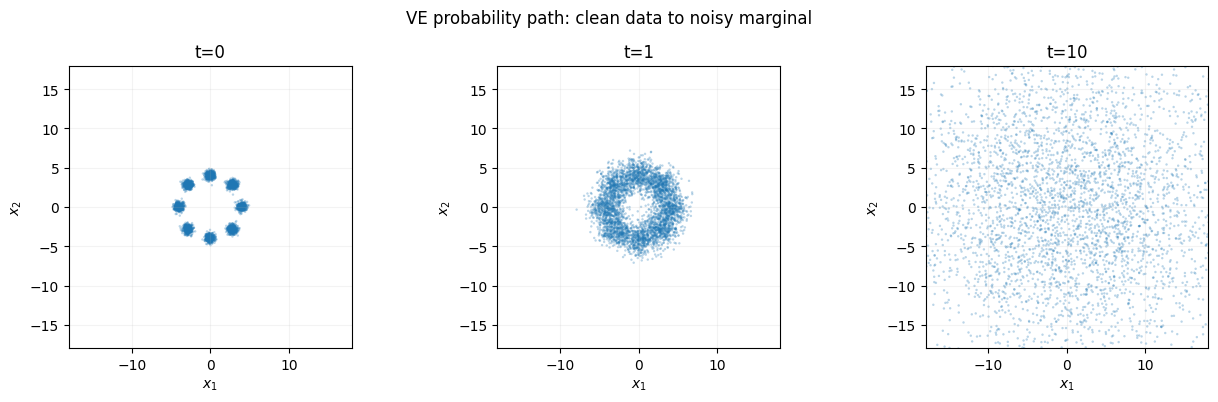

In [2]:
class GaussianMixture2D:
    """
    Eight Gaussian modes distributed on a circle.

    p_data(x) = (1/K) sum_k N(x; mu_k, sigma_data^2 I)

    After VE noising:

    p_t(x) = (1/K) sum_k N(
        x; mu_k, (sigma_data^2 + t^2) I
    )

    Therefore the exact marginal score is available.
    """

    def __init__(
        self,
        num_modes=8,
        radius=4.0,
        data_std=0.3,
        device=DEVICE,
    ):
        self.num_modes = num_modes
        self.radius = radius
        self.data_std = data_std
        self.device = device

        angles = torch.arange(
            num_modes,
            device=device,
            dtype=torch.float32,
        ) * (2.0 * math.pi / num_modes)

        self.centers = torch.stack(
            [
                radius * torch.cos(angles),
                radius * torch.sin(angles),
            ],
            dim=-1,
        )

    def sample_data(self, batch_size: int):
        """
        Sample X0 ~ p_data.
        """
        labels = torch.randint(
            0,
            self.num_modes,
            (batch_size,),
            device=self.device,
        )

        means = self.centers[labels]

        noise = torch.randn(
            batch_size, 2, device=self.device
        )

        return means + self.data_std * noise

    def sample_noisy(self, batch_size: int, t):
        """
        Sample Xt = X0 + tZ.
        """
        x0 = self.sample_data(batch_size)
        z = torch.randn_like(x0)

        if not torch.is_tensor(t):
            t = torch.full(
                (batch_size, 1),
                float(t),
                device=self.device,
            )

        return x0 + t * z

    def sample_marginal(self, batch_size: int, t: float):
        """
        Exact sampling from p_t.
        """
        return self.sample_noisy(batch_size, t)

    def sample_gaussian_prior(self, batch_size: int):
        """
        Approximate prior N(0, T^2 I).

        Note:
            This is not exactly p_T.
        """
        return CFG.T * torch.randn(
            batch_size, 2, device=self.device
        )

    def exact_score(self, x: torch.Tensor, t):
        """
        Exact score:

        score(x,t)
          = sum_k w_k(x,t)
              * (mu_k - x)/(sigma_data^2+t^2)

        Args:
            x: [B,2]
            t: float or [B,1]

        Returns:
            score: [B,2]
        """
        if not torch.is_tensor(t):
            t = torch.full(
                (x.shape[0], 1),
                float(t),
                device=x.device,
                dtype=x.dtype,
            )

        if t.ndim == 1:
            t = t[:, None]

        variance = self.data_std**2 + t**2

        # [B,K,2]
        diff = x[:, None, :] - self.centers[None, :, :]

        # [B,K]
        squared_dist = torch.sum(diff**2, dim=-1)

        # Equal mixture weights and equal covariance:
        # normalization terms cancel in the softmax.
        logits = -squared_dist / (
            2.0 * variance
        )

        weights = torch.softmax(logits, dim=1)

        # Component scores: [B,K,2]
        component_scores = -diff / variance[:, None, :]

        score = torch.sum(
            weights[:, :, None] * component_scores,
            dim=1,
        )

        return score

    def exact_velocity(self, x: torch.Tensor, t):
        """
        Probability Flow ODE for VE SDE:

            dX/dt = -t * score(X,t)
        """
        if not torch.is_tensor(t):
            t_tensor = torch.full(
                (x.shape[0], 1),
                float(t),
                device=x.device,
                dtype=x.dtype,
            )
        else:
            t_tensor = t

        if t_tensor.ndim == 1:
            t_tensor = t_tensor[:, None]

        return -t_tensor * self.exact_score(x, t_tensor)


gmm = GaussianMixture2D(
    num_modes=CFG.num_modes,
    radius=CFG.radius,
    data_std=CFG.data_std,
    device=DEVICE,
)

preview_times = [0.0, 1.0, CFG.T]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, t in zip(axes, preview_times):
    points = gmm.sample_data(4000) if t == 0 else gmm.sample_marginal(4000, t)
    p = to_numpy(points)
    ax.scatter(p[:, 0], p[:, 1], s=3, alpha=0.3, edgecolors="none")
    ax.set(title=f"t={t:g}", xlim=(-18, 18), ylim=(-18, 18), xlabel="$x_1$", ylabel="$x_2$")
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)
fig.suptitle("VE probability path: clean data to noisy marginal")
fig.tight_layout()
plt.show()


## 数值求解器与一致性网络

实验统一使用 Euler、Heun 和 RK4 求解同一个解析 PF ODE。Consistency Model 采用 EDM 风格的 skip/out 预条件化，显式保证边界条件 $f_	heta(x,\epsilon)=x$；EMA 网络作为停止梯度的训练目标。


In [3]:
@torch.no_grad()
def euler_step(
    x: torch.Tensor,
    t: float,
    t_next: float,
    velocity_fn,
):
    """
    One Euler step:

        x_next = x + (t_next-t)*v(x,t)
    """
    dt = t_next - t
    return x + dt * velocity_fn(x, t)


@torch.no_grad()
def heun_step(
    x: torch.Tensor,
    t: float,
    t_next: float,
    velocity_fn,
):
    """
    Second-order Heun method:

        k1 = v(x,t)
        x_pred = x + dt*k1
        k2 = v(x_pred,t_next)
        x_next = x + dt*(k1+k2)/2
    """
    dt = t_next - t

    k1 = velocity_fn(x, t)
    x_pred = x + dt * k1
    k2 = velocity_fn(x_pred, t_next)

    return x + 0.5 * dt * (k1 + k2)


@torch.no_grad()
def rk4_step(
    x: torch.Tensor,
    t: float,
    t_next: float,
    velocity_fn,
):
    """
    Classical fourth-order Runge-Kutta.
    """
    dt = t_next - t

    k1 = velocity_fn(x, t)

    k2 = velocity_fn(
        x + 0.5 * dt * k1,
        t + 0.5 * dt,
    )

    k3 = velocity_fn(
        x + 0.5 * dt * k2,
        t + 0.5 * dt,
    )

    k4 = velocity_fn(
        x + dt * k3,
        t_next,
    )

    return x + dt * (
        k1 + 2*k2 + 2*k3 + k4
    ) / 6.0


@torch.no_grad()
def integrate_ode(
    x: torch.Tensor,
    t_start: float,
    t_end: float,
    velocity_fn,
    num_steps: int = 100,
    method: str = "rk4",
    return_trajectory: bool = False,
):
    """
    Integrate ODE from t_start to t_end.

    Supports forward or backward integration.
    """
    solvers = {
        "euler": euler_step,
        "heun": heun_step,
        "rk4": rk4_step,
    }

    solver = solvers[method]

    times = torch.linspace(
        t_start,
        t_end,
        num_steps + 1,
    ).tolist()

    current = x.clone()

    trajectory = [current.clone()]

    for i in range(num_steps):
        current = solver(
            current,
            times[i],
            times[i + 1],
            velocity_fn,
        )

        if return_trajectory:
            trajectory.append(current.clone())

    if return_trajectory:
        return torch.stack(trajectory, dim=0), times

    return current


In [4]:
class TimeEmbedding(nn.Module):
    """
    Fourier time embedding.

    Input:
        t: [B,1]

    Output:
        embedding: [B,dim]
    """

    def __init__(self, dim=64):
        super().__init__()

        self.dim = dim

        frequencies = torch.exp(
            torch.linspace(
                math.log(1.0),
                math.log(100.0),
                dim // 2,
            )
        )

        self.register_buffer(
            "frequencies",
            frequencies,
        )

    def forward(self, t):
        # Log time is useful for a wide noise range.
        log_t = torch.log(t.clamp_min(1e-5))

        angles = log_t * self.frequencies[None, :]

        return torch.cat(
            [
                torch.sin(angles),
                torch.cos(angles),
            ],
            dim=-1,
        )


class ConsistencyMLP(nn.Module):
    """
    f_theta(x,t)
      = c_skip(t)*x + c_out(t)*F_theta(x,t)

    Boundary:
        f_theta(x,eps) = x
    """

    def __init__(
        self,
        hidden_dim=128,
        num_hidden_layers=3,
        time_dim=64,
        data_std=0.3,
        eps=0.01,
        use_boundary=True,
    ):
        super().__init__()

        self.data_std = data_std
        self.eps = eps
        self.use_boundary = use_boundary

        self.time_embedding = TimeEmbedding(time_dim)

        layers = []

        input_dim = 2 + time_dim

        for i in range(num_hidden_layers):
            layers.append(
                nn.Linear(
                    input_dim if i == 0 else hidden_dim,
                    hidden_dim,
                )
            )
            layers.append(nn.SiLU())

        layers.append(nn.Linear(hidden_dim, 2))

        self.net = nn.Sequential(*layers)

    def forward(self, x, t):
        if not torch.is_tensor(t):
            t = torch.full(
                (x.shape[0], 1),
                float(t),
                device=x.device,
                dtype=x.dtype,
            )

        if t.ndim == 1:
            t = t[:, None]

        t_embed = self.time_embedding(t)

        c_in = torch.rsqrt(t**2 + self.data_std**2)
        h = torch.cat([c_in * x, t_embed], dim=-1)

        prediction = self.net(h)

        if not self.use_boundary:
            return prediction

        delta = t - self.eps

        sigma2 = self.data_std**2

        c_skip = sigma2 / (delta**2 + sigma2)

        c_out = (
            self.data_std * delta
            / torch.sqrt(delta**2 + sigma2)
        )

        return c_skip * x + c_out * prediction


def build_model(use_boundary=True):
    return ConsistencyMLP(
        hidden_dim=CFG.hidden_dim,
        num_hidden_layers=CFG.num_hidden_layers,
        data_std=CFG.model_data_std,
        eps=CFG.eps,
        use_boundary=use_boundary,
    ).to(DEVICE)

class EMA:
    """
    Exponential Moving Average target network.
    """

    def __init__(self, model, decay=0.99):
        self.decay = decay

        self.model = copy.deepcopy(model)

        self.model.eval()

        for p in self.model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model, decay=None):
        decay = self.decay if decay is None else decay

        for ema_param, param in zip(
            self.model.parameters(),
            model.parameters(),
        ):
            ema_param.mul_(decay).add_(
                param,
                alpha=1.0 - decay,
            )

def make_time_grid(num_steps: int):
    """Karras-style grid, concentrated near the low-noise boundary."""
    ramp = torch.linspace(0, 1, num_steps + 1, device=DEVICE)
    rho = CFG.time_grid_rho
    return (
        CFG.eps**(1 / rho)
        + ramp * (CFG.T**(1 / rho) - CFG.eps**(1 / rho))
    )**rho


def get_schedule_num_steps(
    iteration: int,
    total_steps: int,
):
    """
    Gradually increase time-grid resolution.

    Uses a simple smooth schedule for this experiment.
    """
    progress = iteration / max(total_steps - 1, 1)

    start = CFG.schedule_start
    end = CFG.schedule_end

    value = math.sqrt(
        (1.0 - progress) * start**2
        + progress * end**2
    )

    return max(2, int(round(value)))


def sample_time_pair(
    batch_size: int,
    num_steps: int,
):
    """
    Sample adjacent time levels for each sample.

    Returns:
        t_low:  [B,1]
        t_high: [B,1]
    """
    grid = make_time_grid(num_steps)

    indices = torch.randint(
        0,
        num_steps,
        (batch_size,),
        device=DEVICE,
    )

    t_low = grid[indices, None]
    t_high = grid[indices + 1, None]

    return t_low, t_high


model_preview = build_model()
print(model_preview)
print(f"Trainable parameters: {sum(p.numel() for p in model_preview.parameters()):,}")


ConsistencyMLP(
  (time_embedding): TimeEmbedding()
  (net): Sequential(
    (0): Linear(in_features=66, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)
Trainable parameters: 41,858


## 统一训练、评价与采样工具

CD 与 CT 共用网络、优化器、EMA 和时间网格，只改变相邻低噪声状态的构造方式。评价同时报告教师终点 MSE、MMD、模态覆盖率和有效样本比例，避免仅凭训练 loss 判断生成质量。


In [5]:
def train_consistency_model(
    gmm,
    method="cd",
    train_steps=None,
    ema_decay=None,
    use_schedule=False,
    shared_noise=True,
    use_boundary=True,
    teacher_solver="heun",
    verbose=True,
):
    """
    Train CD or CT.

    method:
        "cd": teacher ODE local step
        "ct": same-noise adjacent noising states

    shared_noise:
        Only relevant for CT.
        False creates an intentionally incorrect
        independent-noise ablation.

    teacher_solver:
        "euler" or "heun"
    """
    if train_steps is None:
        train_steps = CFG.train_steps

    if ema_decay is None:
        ema_decay = CFG.ema_decay

    model = build_model(
        use_boundary=use_boundary
    )

    ema = EMA(model, decay=ema_decay)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=CFG.lr,
    )

    history = {
        "step": [],
        "loss": [],
        "num_time_steps": [],
    }

    model.train()

    start_time = time.time()

    for step in range(train_steps):

        if use_schedule:
            num_steps = get_schedule_num_steps(
                step,
                train_steps,
            )
        else:
            num_steps = CFG.num_time_steps

        x0 = gmm.sample_data(CFG.batch_size)

        z = torch.randn_like(x0)

        t_low, t_high = sample_time_pair(
            CFG.batch_size,
            num_steps,
        )

        x_high = x0 + t_high * z

        if method == "ct":

            if shared_noise:
                z_low = z
            else:
                z_low = torch.randn_like(z)

            x_low = x0 + t_low * z_low

        elif method == "cd":

            # The teacher velocity is only used by CD.
            # Each sample may have a different time pair,
            # so the solver is applied in a vectorized way.
            dt = t_low - t_high

            with torch.no_grad():

                v1 = gmm.exact_velocity(
                    x_high,
                    t_high,
                )

                if teacher_solver == "euler":
                    x_low = x_high + dt * v1

                elif teacher_solver == "heun":
                    x_pred = x_high + dt * v1

                    v2 = gmm.exact_velocity(
                        x_pred,
                        t_low,
                    )

                    x_low = x_high + 0.5 * dt * (
                        v1 + v2
                    )

                else:
                    raise ValueError(
                        f"Unknown solver: {teacher_solver}"
                    )

        else:
            raise ValueError(
                f"Unknown method: {method}"
            )

        # Online prediction.
        pred = model(x_high, t_high)

        # Stop-gradient target.
        with torch.no_grad():
            target = ema.model(x_low, t_low)

        # Adjacent intervals have very different widths on the Karras grid.
        # Inverse-step weighting prevents wide high-noise intervals from dominating.
        per_sample_loss = (pred - target).square().mean(dim=-1)
        interval = (t_high - t_low).squeeze(-1).clamp_min(1e-6)
        weights = interval.reciprocal()
        weights = weights / weights.mean().detach()
        loss = (weights * per_sample_loss).mean()

        optimizer.zero_grad(set_to_none=True)

        loss.backward()

        optimizer.step()

        ema.update(model)

        history["step"].append(step + 1)
        history["loss"].append(loss.item())
        history["num_time_steps"].append(num_steps)

        if verbose and (
            step == 0
            or (step + 1) % 1000 == 0
            or step + 1 == train_steps
        ):
            elapsed = time.time() - start_time

            print(
                f"[{method.upper()}] "
                f"Step {step+1:5d}/{train_steps} | "
                f"Loss {loss.item():.6f} | "
                f"N={num_steps:3d} | "
                f"Time {elapsed:.1f}s"
            )

    model.eval()
    ema.model.eval()

    return model, ema.model, history


In [6]:
@torch.no_grad()
def endpoint_mse(
    model,
    gmm,
    num_samples=None,
    reference_steps=None,
):
    """
    Compare model output with high-accuracy
    RK4 Probability Flow ODE endpoint.
    """
    if num_samples is None:
        num_samples = CFG.eval_samples

    if reference_steps is None:
        reference_steps = CFG.reference_steps

    total_error = 0.0
    total_count = 0

    while total_count < num_samples:

        batch_size = min(
            CFG.eval_batch_size,
            num_samples - total_count,
        )

        x0 = gmm.sample_data(batch_size)

        z = torch.randn_like(x0)

        # Random evaluation time.
        t = CFG.eps + (
            CFG.T - CFG.eps
        ) * torch.rand(
            batch_size, 1, device=DEVICE
        )

        x_t = x0 + t * z

        # Different samples have different start times.
        # Integrate them together with normalized time s.
        # t(s) = t + s*(eps-t), s in [0,1].
        dt_total = CFG.eps - t

        def normalized_velocity(x, s):
            current_t = t + s * dt_total

            return dt_total * gmm.exact_velocity(
                x,
                current_t,
            )

        reference = integrate_ode(
            x_t,
            0.0,
            1.0,
            normalized_velocity,
            num_steps=reference_steps,
            method="rk4",
        )

        prediction = model(x_t, t)

        error = torch.sum(
            (prediction - reference)**2,
            dim=-1,
        )

        total_error += error.sum().item()
        total_count += batch_size

    return total_error / total_count


@torch.no_grad()
def endpoint_mse_at_time(model, gmm, t=CFG.T, num_samples=1024, reference_steps=None):
    """Endpoint MSE at a fixed noise level; t=T directly measures one-step denoising."""
    if reference_steps is None:
        reference_steps = CFG.reference_steps
    x_t = gmm.sample_marginal(num_samples, t)
    reference = integrate_ode(
        x_t, t, CFG.eps, gmm.exact_velocity,
        num_steps=reference_steps, method="rk4",
    )
    prediction = model(x_t, t)
    return torch.sum((prediction - reference)**2, dim=-1).mean().item()


@torch.no_grad()
def consistency_error(
    model,
    gmm,
    num_samples=1024,
    num_steps=200,
):
    """
    Measure model self-consistency along true PF ODE
    trajectories.
    """
    x_T = gmm.sample_marginal(
        num_samples,
        CFG.T,
    )

    trajectory, times = integrate_ode(
        x_T,
        CFG.T,
        CFG.eps,
        gmm.exact_velocity,
        num_steps=num_steps,
        method="rk4",
        return_trajectory=True,
    )

    final = model(
        trajectory[-1],
        CFG.eps,
    )

    errors = []

    for i, t in enumerate(times):
        pred = model(
            trajectory[i],
            t,
        )

        error = torch.mean(
            torch.sum((pred - final)**2, dim=-1)
        )

        errors.append(error.item())

    return np.array(times), np.array(errors)


def compute_mmd(
    x: torch.Tensor,
    y: torch.Tensor,
    bandwidths=(0.2, 0.5, 1.0, 2.0, 4.0),
):
    """
    Multi-scale RBF MMD^2.

    Uses the biased nonnegative estimator.
    Suitable for comparing 2D sample distributions.
    """
    x = x.detach()
    y = y.detach()

    xx = torch.cdist(x, x).square()
    yy = torch.cdist(y, y).square()
    xy = torch.cdist(x, y).square()

    mmd = 0.0

    for bandwidth in bandwidths:

        gamma = 1.0 / (2.0 * bandwidth**2)

        k_xx = torch.exp(-gamma * xx)
        k_yy = torch.exp(-gamma * yy)
        k_xy = torch.exp(-gamma * xy)

        mmd += (
            k_xx.mean()
            + k_yy.mean()
            - 2.0 * k_xy.mean()
        )

    return float(
        (mmd / len(bandwidths)).item()
    )


@torch.no_grad()
def mode_coverage(
    samples,
    gmm,
    threshold=1.0,
):
    """
    Assign each generated point to its nearest mode.

    A sample counts as belonging to a mode only if
    its distance to that mode is below threshold.

    Returns:
        coverage: fraction of modes covered
        frequencies: normalized counts
        valid_ratio: fraction of samples near a mode
    """
    distances = torch.cdist(
        samples,
        gmm.centers,
    )

    min_dist, labels = distances.min(dim=1)

    valid = min_dist < threshold

    counts = torch.bincount(
        labels[valid],
        minlength=gmm.num_modes,
    ).float()

    min_count = max(5, int(0.005 * len(samples)))

    coverage = (
        (counts >= min_count).float().mean().item()
    )

    frequencies = counts / counts.sum().clamp_min(1)

    valid_ratio = valid.float().mean().item()

    return (
        coverage,
        to_numpy(frequencies),
        valid_ratio,
    )

@torch.no_grad()
def sample_one_step(
    model,
    gmm,
    num_samples=2048,
    exact_prior=True,
):
    """
    One-step consistency sampling.
    """
    if exact_prior:
        x_T = gmm.sample_marginal(
            num_samples,
            CFG.T,
        )
    else:
        x_T = gmm.sample_gaussian_prior(
            num_samples
        )

    return model(x_T, CFG.T)


@torch.no_grad()
def sample_multi_step(
    model,
    gmm,
    num_samples=2048,
    noise_levels=None,
    exact_prior=True,
):
    """
    Multi-step consistency sampling:

        predict endpoint
        -> re-noise
        -> predict endpoint
    """
    if noise_levels is None:
        noise_levels = []

    if exact_prior:
        x = gmm.sample_marginal(
            num_samples,
            CFG.T,
        )
    else:
        x = gmm.sample_gaussian_prior(
            num_samples
        )

    # First network evaluation.
    x = model(x, CFG.T)

    for tau in noise_levels:

        noise_std = math.sqrt(
            max(tau**2 - CFG.eps**2, 0.0)
        )

        x = x + noise_std * torch.randn_like(x)

        x = model(x, tau)

    return x


# 三、实验 1：验证 PF ODE 的自一致性

## 3.1 实验目的

验证论文最基础的结论：

$$
\boxed{
f^*(X_t,t)=X_\epsilon
}
\tag{9}
$$

也就是说，同一条 PF ODE 轨迹上的任意状态，都应该映射到同一个终点。

这个实验暂时不训练神经网络，而是直接利用解析 Score 和数值积分构造真实的一致性函数。

## 3.2 实验步骤

**第一步：采样初始噪声。**

$$
X_T\sim p_T
$$

由于我们的 GMM 具有解析形式，可以直接从 $p_T$ 采样。

**第二步：求解 PF ODE。**

$$
\frac{dX_t}{dt}=v^*(X_t,t)
$$

使用高精度 RK4，积分：

$$
T\rightarrow\epsilon
$$

记录轨迹：

$$
X_T,X_{t_{N-1}},\ldots,X_\epsilon
$$

**第三步：在同一条轨迹上选择多个中间状态。**

例如：

$$
t\in\{10,8,6,4,2,1,0.1\}
$$

分别从这些状态出发，再次积分到 $\epsilon$：

$$
\widehat X_\epsilon^{(t)}
=
\Phi_{t\rightarrow\epsilon}(X_t)
$$

**第四步：计算一致性误差。**

$$
\boxed{
E_{\mathrm{consistency}}
=
\frac1M
\sum_{i=1}^{M}
\left\|
\widehat X_\epsilon^{(t_i)}
-
X_\epsilon
\right\|^2
}
\tag{10}
$$

## 3.3 预期结果

绘制两张图。

**图 1：PF ODE 轨迹图**

在二维平面展示：

- 八个真实数据模态。
- 从高斯噪声出发的 ODE 轨迹。
- 不同轨迹最终到达的位置。

**图 2：一致性误差随积分步长变化**

横轴：

$$
h
$$

纵轴：

$$
E_{\mathrm{consistency}}
$$

随着数值积分精度提高，一致性误差应该逐渐降低。

需要注意，真实 ODE 终点具有严格一致性，但数值积分得到的终点只具有近似一致性。

---



Experiment 1: PF ODE Consistency


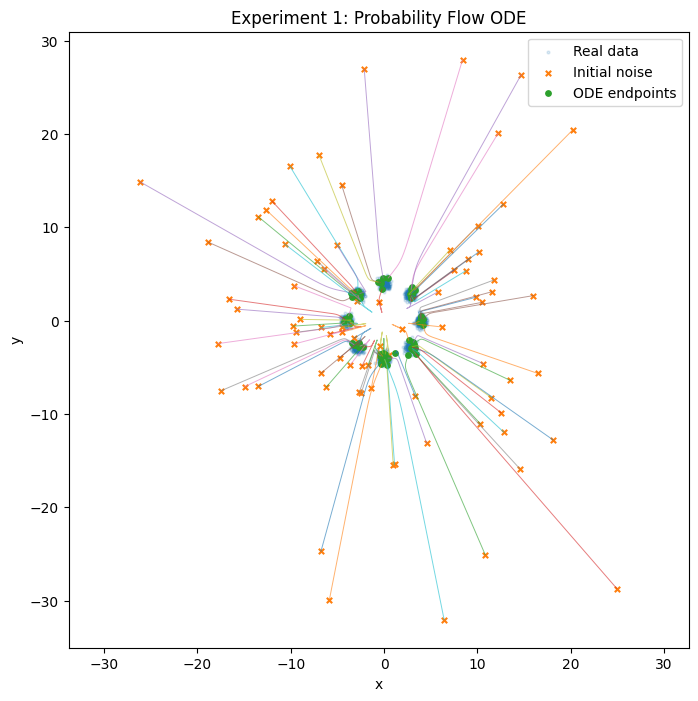

t=10.0000 | Endpoint MSE=0.0000000000
t=8.0020 | Endpoint MSE=0.0000000005
t=6.0040 | Endpoint MSE=0.0000000064


t=4.0060 | Endpoint MSE=0.0000000043
t=2.0080 | Endpoint MSE=0.0000000000
t=0.5095 | Endpoint MSE=0.0000000000
exp1_consistency.csv


,time,endpoint_mse
0,10.0000,0.000000e+00
1,8.0020,5.182995e-10
2,6.0040,6.378046e-09
3,4.0060,4.287223e-09
4,2.0080,2.184158e-11
5,0.5095,1.671254e-14


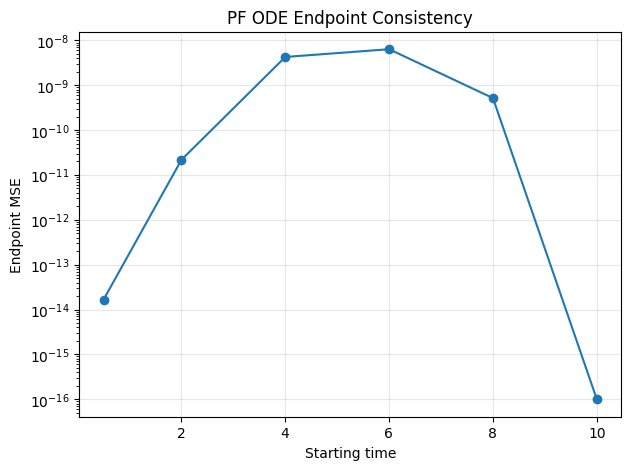

In [7]:
def experiment_1_pf_ode(gmm):
    print("\n" + "=" * 70)
    print("Experiment 1: PF ODE Consistency")
    print("=" * 70)

    num_samples = 80

    x_T = gmm.sample_marginal(
        num_samples,
        CFG.T,
    )

    trajectory, times = integrate_ode(
        x_T,
        CFG.T,
        CFG.eps,
        gmm.exact_velocity,
        num_steps=400,
        method="rk4",
        return_trajectory=True,
    )

    trajectory_np = to_numpy(trajectory)

    data = to_numpy(
        gmm.sample_data(2000)
    )

    plt.figure(figsize=(8, 8))

    plt.scatter(
        data[:, 0],
        data[:, 1],
        s=4,
        alpha=0.15,
        label="Real data",
    )

    for i in range(num_samples):
        plt.plot(
            trajectory_np[:, i, 0],
            trajectory_np[:, i, 1],
            linewidth=0.7,
            alpha=0.6,
        )

    plt.scatter(
        trajectory_np[0, :, 0],
        trajectory_np[0, :, 1],
        s=15,
        marker="x",
        label="Initial noise",
    )

    plt.scatter(
        trajectory_np[-1, :, 0],
        trajectory_np[-1, :, 1],
        s=15,
        label="ODE endpoints",
    )

    plt.title("Experiment 1: Probability Flow ODE")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis("equal")
    plt.legend()

    save_figure("exp1_pf_ode_trajectories.png")

    # Verify endpoint consistency:
    # From intermediate points, integrate again to eps.
    selected_indices = [0, 80, 160, 240, 320, 380]

    endpoint = trajectory[-1]

    results = []

    for idx in selected_indices:

        current_t = times[idx]
        current_x = trajectory[idx]

        recovered = integrate_ode(
            current_x,
            current_t,
            CFG.eps,
            gmm.exact_velocity,
            num_steps=max(20, 400 - idx),
            method="rk4",
        )

        error = torch.mean(
            torch.sum(
                (recovered - endpoint)**2,
                dim=-1,
            )
        ).item()

        results.append(
            {
                "time": current_t,
                "endpoint_mse": error,
            }
        )

        print(
            f"t={current_t:.4f} | "
            f"Endpoint MSE={error:.10f}"
        )

    save_csv(
        results,
        "exp1_consistency.csv",
    )

    plt.figure(figsize=(7, 5))

    plt.semilogy(
        [r["time"] for r in results],
        [max(r["endpoint_mse"], 1e-16) for r in results],
        marker="o",
    )

    plt.xlabel("Starting time")
    plt.ylabel("Endpoint MSE")
    plt.title("PF ODE Endpoint Consistency")
    plt.grid(alpha=0.3)

    save_figure("exp1_consistency_error.png")

experiment_1_pf_ode(gmm)


# 四、实验 2：训练 Consistency Distillation

## 4.1 实验目的

验证：

**通过相邻时间的教师 ODE 状态监督，Consistency Model 能够学习整条 ODE 的终点映射。**

## 4.2 CD 训练流程

首先采样：

$$
X_0\sim p_{\mathrm{data}}
$$

$$
Z\sim\mathcal N(0,I)
$$

随机选择：

$$
n\in\{1,\ldots,N-1\}
$$

构造：

$$
X_{t_{n+1}}=X_0+t_{n+1}Z
$$

使用教师 Solver：

$$
\widehat X_{t_n}
=
\operatorname{Solver}
(X_{t_{n+1}},t_{n+1},t_n)
$$

随后计算：

$$
\boxed{
\mathcal L_{\mathrm{CD}}
=
\mathbb E
\left\|
f_\theta(X_{t_{n+1}},t_{n+1})
-
\operatorname{sg}
\left[
f_{\theta^-}(\widehat X_{t_n},t_n)
\right]
\right\|^2
}
\tag{11}
$$

其中：

$$
\operatorname{sg}
$$

表示 Stop Gradient。

使用 EMA 更新：

$$
\theta^-\leftarrow
\mu\theta^-+(1-\mu)\theta
$$

建议初始参数：

| 参数 | 建议值 |
|---|---|
| Batch Size | 512 |
| Learning Rate | $10^{-3}$ |
| Optimizer | Adam |
| Training Steps | 10000 |
| 时间网格数 $N$ | 100 |
| EMA | 0.99 |
| Teacher Solver | Heun |
| Loss | MSE |

这是二维验证实验的起始配置，具体训练步数需要根据收敛曲线调整。

## 4.3 如何评价模型是否学到了正确终点？

准备独立测试集：

$$
\{(X_t^{(i)},t_i)\}_{i=1}^{M}
$$

使用高精度 RK4 计算真实终点：

$$
X_{\epsilon,\mathrm{GT}}^{(i)}
=
\Phi_{t_i\rightarrow\epsilon}
(X_t^{(i)})
$$

网络预测：

$$
\widehat X_\epsilon^{(i)}
=
f_\theta(X_t^{(i)},t_i)
$$

计算：

$$
\boxed{
E_{\mathrm{endpoint}}
=
\frac1M
\sum_{i=1}^{M}
\left\|
\widehat X_\epsilon^{(i)}
-
X_{\epsilon,\mathrm{GT}}^{(i)}
\right\|^2
}
\tag{12}
$$

同时评价生成分布：

$$
X_T\sim p_T
$$

$$
\widehat X_\epsilon=f_\theta(X_T,T)
$$

与真实的 $p_\epsilon$ 比较。

这里建议使用：

- MMD：衡量生成分布与真实分布的差异。
- Mode Coverage：统计八个模态是否被覆盖。
- Mode Frequency：检查八个模态的生成比例。
- Endpoint MSE：衡量模型对教师 ODE 的逼近精度。

**需要注意：生成分布接近真实分布，不代表模型学习了正确的 ODE 终点映射。**

因此，Endpoint MSE 和 MMD 必须同时报告。

## 4.4 预期结果

训练过程中：

$$
E_{\mathrm{endpoint}}\downarrow
$$

生成样本逐渐聚集到八个模态附近。

理想情况下：

$$
f_\theta(X_T,T)
\approx
\Phi_{T\rightarrow\epsilon}(X_T)
$$

同时：

$$
p_\theta\approx p_\epsilon
$$

---

# 五、实验 3：训练 Consistency Training

这是整套实验最值得关注的部分。

## 5.1 实验目的

验证：

**即使完全不使用教师 Score Network，也可以通过相邻噪声状态训练一致性模型。**

同时与 CD 比较：

- 收敛速度。
- 终点误差。
- 生成分布。
- 训练稳定性。

## 5.2 CT 训练流程

采样：

$$
X_0\sim p_{\mathrm{data}}
$$

$$
Z\sim\mathcal N(0,I)
$$

选择相邻时间：

$$
t_n<t_{n+1}
$$

构造：

$$
X_{t_n}=X_0+t_nZ
$$

$$
X_{t_{n+1}}=X_0+t_{n+1}Z
$$

训练：

$$
\boxed{
\mathcal L_{\mathrm{CT}}
=
\mathbb E
\left\|
f_\theta(X_{t_{n+1}},t_{n+1})
-
\operatorname{sg}
\left[
f_{\theta^-}(X_{t_n},t_n)
\right]
\right\|^2
}
\tag{13}
$$

不需要教师 Solver。

## 5.3 为什么建议增加时间网格调度？

固定较小的 $N$，意味着：

$$
\Delta t
$$

较大。

这会造成较明显的离散化偏差。

但如果一开始就选择非常大的 $N$，那么：

$$
X_{t_{n+1}}\approx X_{t_n}
$$

两个网络输出可能非常接近，训练信号较弱。

因此建议进行两组对照。

**CT-Fixed：**

$$
N=100
$$

始终不变。

**CT-Schedule：**

训练初期：

$$
N=10
$$

随后逐渐增加到：

$$
N=200
$$

比较两种策略的训练曲线。

实际实现采用 $
ho=7$ 的 Karras 非均匀时间网格，使更多层级集中在低噪声区域；同时使用 $1/(t_{n+1}-t_n)$ 相对权重平衡不同宽度的相邻区间。这两项设置主要改善从局部一致性向全局一步映射的传播。

## 5.4 增加一个关键对照：不同噪声耦合

训练三个 CT 模型。

| 模型 | 相邻时间状态 | 目的 |
|---|---|---|
| CT-Shared | 使用同一个 $Z$ | 标准 CT |
| CT-Independent | 使用独立 $Z_1,Z_2$ | 验证共享噪声的重要性 |
| CD-Teacher | 使用真实 PF ODE 局部更新 | 与 CD 对照 |

对于 CT-Independent：

$$
X_{t_{n+1}}=X_0+t_{n+1}Z_1
$$

$$
X_{t_n}=X_0+t_nZ_2
$$

由于：

$$
Z_1\ne Z_2
$$

即使：

$$
t_{n+1}-t_n\rightarrow0
$$

也无法保证两个状态接近。

因此预期：

$$
E_{\mathrm{CT\text{-}Shared}}
<
E_{\mathrm{CT\text{-}Independent}}
$$

这里指充分训练后的终点误差，而不是训练损失；实际排序需要实验确认。

## 5.5 预期结果

CD 通常更容易获得准确的 ODE 终点预测。

CT-Shared 应该能够逐渐学习有效的生成映射。

CT-Independent 可能出现明显的训练困难或生成质量下降。

需要强调：

CT 与 CD 的性能差异并不是由某个简单的理论不等式直接保证的，需要通过实验验证。

---



Experiment 2 & 3: CD vs CT


[CD] Step     1/10000 | Loss 0.000112 | N=100 | Time 0.1s


[CD] Step  1000/10000 | Loss 0.000033 | N=100 | Time 1.3s


[CD] Step  2000/10000 | Loss 0.000009 | N=100 | Time 2.6s


[CD] Step  3000/10000 | Loss 0.000032 | N=100 | Time 3.8s


...

[CT] Step  6000/10000 | Loss 0.000155 | N=155 | Time 6.3s


[CT] Step  7000/10000 | Loss 0.000185 | N=167 | Time 7.4s


[CT] Step  8000/10000 | Loss 0.000164 | N=179 | Time 8.5s


[CT] Step  9000/10000 | Loss 0.000160 | N=190 | Time 9.5s


[CT] Step 10000/10000 | Loss 0.000122 | N=200 | Time 10.6s


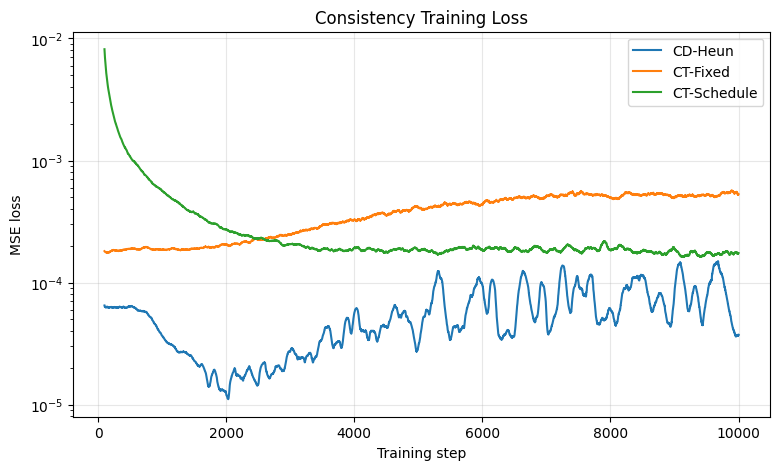

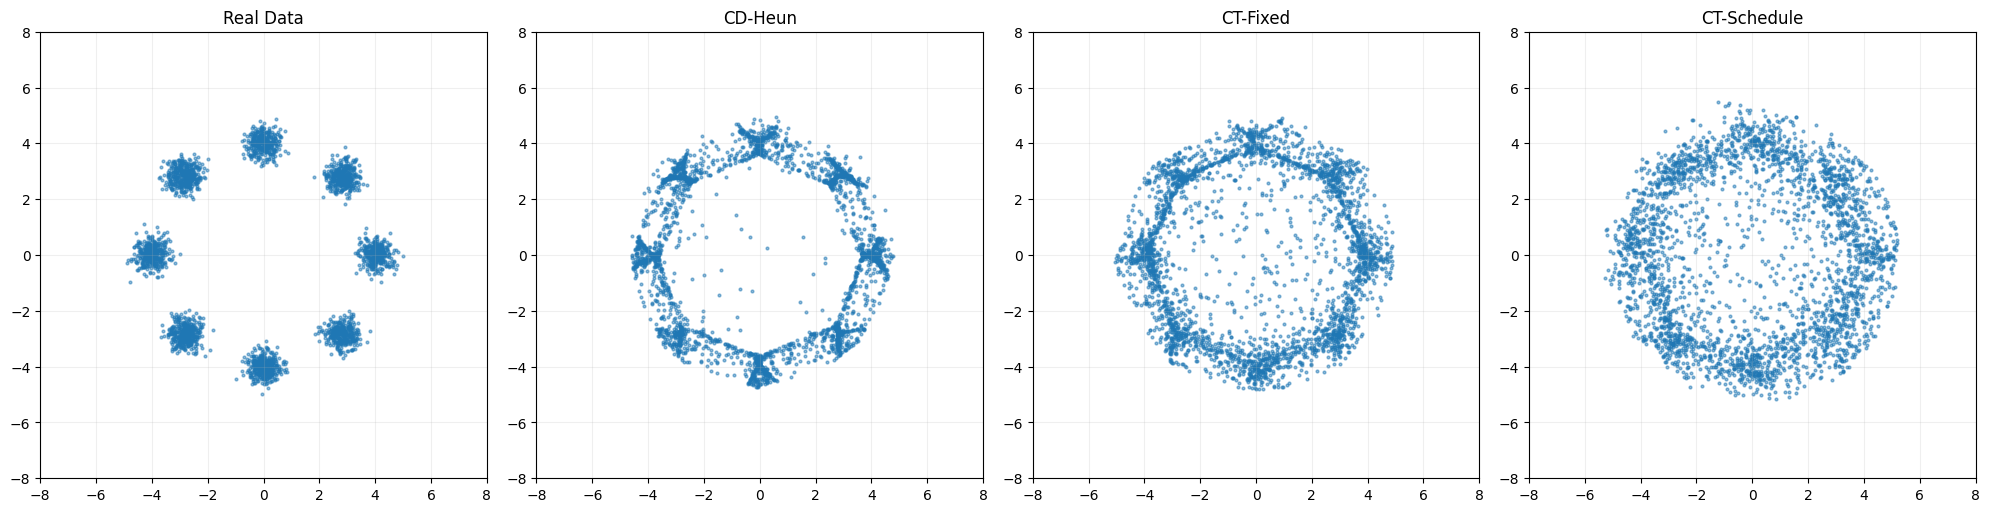

Real-vs-real MMD baseline: 0.000691

Evaluating CD-Heun ...


CD-Heun: Endpoint MSE(random t)=0.073752, Endpoint MSE(T)=0.128326, MMD=0.002164, Coverage=1.000, Valid=0.862
Mode frequencies: [0.126 0.127 0.126 0.121 0.125 0.108 0.131 0.135]

Evaluating CT-Fixed ...


CT-Fixed: Endpoint MSE(random t)=0.241887, Endpoint MSE(T)=0.325915, MMD=0.009230, Coverage=1.000, Valid=0.673
Mode frequencies: [0.131 0.13  0.116 0.118 0.125 0.129 0.122 0.129]

Evaluating CT-Schedule ...


CT-Schedule: Endpoint MSE(random t)=0.285130, Endpoint MSE(T)=0.507854, MMD=0.013087, Coverage=1.000, Valid=0.543
Mode frequencies: [0.095 0.122 0.13  0.134 0.138 0.127 0.139 0.114]
exp2_exp3_evaluation.csv


,model,endpoint_mse_random_t,endpoint_mse_T,mmd_over_floor,mmd,mode_coverage,valid_ratio
0,CD-Heun,0.073752,0.128326,0.001473,0.002164,1.0,0.862305
1,CT-Fixed,0.241887,0.325915,0.008540,0.009230,1.0,0.673340
2,CT-Schedule,0.285130,0.507854,0.012396,0.013087,1.0,0.543457


In [8]:
def plot_training_curves(histories):
    plt.figure(figsize=(9, 5))

    for name, history in histories.items():

        steps = np.array(history["step"])
        losses = np.array(history["loss"])

        # Moving average for readability.
        window = min(100, len(losses))

        smoothed = np.convolve(
            losses,
            np.ones(window) / window,
            mode="valid",
        )

        plt.plot(
            steps[window - 1:],
            smoothed,
            label=name,
        )

    plt.xlabel("Training step")
    plt.ylabel("MSE loss")
    plt.title("Consistency Training Loss")
    plt.yscale("log")
    plt.legend()
    plt.grid(alpha=0.3)

    save_figure("exp2_exp3_training_curves.png")


def plot_generated_samples(
    gmm,
    models,
    num_samples=3000,
):
    """
    Plot generated samples from different models.
    """
    real = to_numpy(
        gmm.sample_data(num_samples)
    )

    all_samples = {
        "Real Data": real,
    }

    for name, model in models.items():
        generated = sample_one_step(
            model,
            gmm,
            num_samples=num_samples,
        )

        all_samples[name] = to_numpy(generated)

    num_plots = len(all_samples)

    fig, axes = plt.subplots(
        1,
        num_plots,
        figsize=(5 * num_plots, 5),
    )

    if num_plots == 1:
        axes = [axes]

    for ax, (name, samples) in zip(
        axes,
        all_samples.items(),
    ):
        ax.scatter(
            samples[:, 0],
            samples[:, 1],
            s=4,
            alpha=0.5,
        )

        ax.set_title(name)
        ax.set_xlim(-8, 8)
        ax.set_ylim(-8, 8)
        ax.set_aspect("equal")
        ax.grid(alpha=0.2)

    plt.tight_layout()

    save_figure("exp2_exp3_generated_samples.png")


def experiment_2_3_training(gmm):
    print("\n" + "=" * 70)
    print("Experiment 2 & 3: CD vs CT")
    print("=" * 70)

    models = {}
    histories = {}

    # CD with Heun teacher.
    cd_model, cd_ema, cd_history = train_consistency_model(
        gmm,
        method="cd",
        teacher_solver="heun",
    )

    models["CD-Heun"] = cd_ema
    histories["CD-Heun"] = cd_history

    # CT with fixed time grid.
    ct_model, ct_ema, ct_history = train_consistency_model(
        gmm,
        method="ct",
        use_schedule=False,
        shared_noise=True,
    )

    models["CT-Fixed"] = ct_ema
    histories["CT-Fixed"] = ct_history

    # CT with progressively refined time grid.
    ct_schedule_model, ct_schedule_ema, ct_schedule_history = (
        train_consistency_model(
            gmm,
            method="ct",
            use_schedule=True,
            shared_noise=True,
        )
    )

    models["CT-Schedule"] = ct_schedule_ema
    histories["CT-Schedule"] = ct_schedule_history

    plot_training_curves(histories)

    plot_generated_samples(gmm, models)

    results = []

    reference_data = gmm.sample_marginal(
        CFG.eval_samples,
        CFG.eps,
    )

    reference_data_2 = gmm.sample_marginal(CFG.eval_samples, CFG.eps)
    mmd_floor = compute_mmd(reference_data, reference_data_2)
    print(f"Real-vs-real MMD baseline: {mmd_floor:.6f}")

    for name, model in models.items():

        print(f"\nEvaluating {name} ...")

        endpoint_error = endpoint_mse(
            model,
            gmm,
        )
        endpoint_error_T = endpoint_mse_at_time(
            model, gmm, t=CFG.T,
        )

        generated = sample_one_step(
            model,
            gmm,
            num_samples=CFG.eval_samples,
        )

        mmd = compute_mmd(
            generated,
            reference_data,
        )

        coverage, frequencies, valid_ratio = mode_coverage(
            generated,
            gmm,
        )

        results.append(
            {
                "model": name,
                "endpoint_mse_random_t": endpoint_error,
                "endpoint_mse_T": endpoint_error_T,
                "mmd_over_floor": mmd - mmd_floor,
                "mmd": mmd,
                "mode_coverage": coverage,
                "valid_ratio": valid_ratio,
            }
        )

        print(
            f"{name}: "
            f"Endpoint MSE(random t)={endpoint_error:.6f}, "
            f"Endpoint MSE(T)={endpoint_error_T:.6f}, "
            f"MMD={mmd:.6f}, "
            f"Coverage={coverage:.3f}, "
            f"Valid={valid_ratio:.3f}"
        )

        print(
            "Mode frequencies:",
            np.round(frequencies, 3),
        )

    save_csv(
        results,
        "exp2_exp3_evaluation.csv",
    )

    return models

models = experiment_2_3_training(gmm)


# 六、实验 4：验证 CD 与 CT 的渐近关系

这是整套实验中**数学验证最直接的一组**。

## 6.1 论文结论

在论文的相应条件下：

$$
\boxed{
\mathcal L_{\mathrm{CD}}^N
=
\mathcal L_{\mathrm{CT}}^N
+
o(\Delta t)
}
\tag{14}
$$

我们希望直接观察：

$$
\Delta t\rightarrow0
$$

时，两种 Loss 的差异如何变化。

## 6.2 为什么不能直接比较两个独立训练模型的 Loss？

因为两个模型的参数不同：

$$
\theta_{\mathrm{CD}}\ne\theta_{\mathrm{CT}}
$$

即使：

$$
\mathcal L_{\mathrm{CD}}
\ne
\mathcal L_{\mathrm{CT}}
$$

也不能说明定理错误。

所以实验必须：

**固定同一个 Online Network、同一个 Target Network，使用相同的数据分布，只改变相邻状态的构造方式。**

为了降低统计噪声，建议固定模型参数，使用大量 Monte Carlo 样本估计损失。

## 6.3 实验步骤

选择：

$$
h\in
\{0.5,0.25,0.125,0.0625,0.03125\}
$$

对于每个 $h$，固定一个时间：

$$
t=5
$$

构造：

$$
X_t=X_0+tZ
$$

**CD 状态：**

$$
Y_{\mathrm{CD}}
=
X_t-hv^*(X_t,t)
$$

**CT 状态：**

$$
Y_{\mathrm{CT}}
=
X_t-hZ
$$

固定：

$$
f_\theta,\quad f_{\theta^-}
$$

计算：

$$
L_{\mathrm{CD}}(h)
=
\mathbb E
\left\|
f_\theta(X_t,t)
-
f_{\theta^-}(Y_{\mathrm{CD}},t-h)
\right\|^2
\tag{15}
$$

$$
L_{\mathrm{CT}}(h)
=
\mathbb E
\left\|
f_\theta(X_t,t)
-
f_{\theta^-}(Y_{\mathrm{CT}},t-h)
\right\|^2
\tag{16}
$$

定义：

$$
\boxed{
D(h)=
|L_{\mathrm{CD}}(h)-L_{\mathrm{CT}}(h)|
}
\tag{17}
$$

绘制：

$$
\log D(h)
$$

关于：

$$
\log h
$$

的曲线。

## 6.4 预期结果

对于足够光滑的网络和平方 L2 损失，在固定 $t$ 的局部比较中，两个损失的一阶项相同，因此通常预期：

$$
\boxed{
D(h)=O(h^2)
}
\tag{18}
$$

于是：

$$
\log D(h)
\approx
2\log h+C
$$

Log-Log 曲线的斜率应接近 2。

但这里需要区分两个结论：

- **论文结论**：在其定理假设下，完整离散 CD/CT 目标具有相应的渐近关系。
- **本实验结论**：固定时间、固定网络、使用 Euler 和平方 L2 损失时，局部损失差异呈现二阶趋势。

后者是我们额外设计的、更容易数值验证的特例。

为了进一步排除教师积分误差，还可以分别使用解析速度的 Euler 和高精度 RK4 构造 CD 状态，观察高阶误差是否影响斜率。

---



Experiment 4: CD vs CT Asymptotic Equivalence
h=0.500000 | CD=0.04851862 | CT=0.05834245 | |Diff|=0.00982383
h=0.250000 | CD=0.04485914 | CT=0.04696950 | |Diff|=0.00211035
h=0.125000 | CD=0.03492122 | CT=0.03542512 | |Diff|=0.00050390
h=0.062500 | CD=0.02508345 | CT=0.02519991 | |Diff|=0.00011646
h=0.031250 | CD=0.02129384 | CT=0.02132458 | |Diff|=0.00003074


h=0.015625 | CD=0.01981719 | CT=0.01982529 | |Diff|=0.00000810
exp4_asymptotic_loss.csv


,h,loss_cd,loss_ct,difference
0,0.500000,0.048519,0.058342,0.009824
1,0.250000,0.044859,0.046969,0.002110
2,0.125000,0.034921,0.035425,0.000504
3,0.062500,0.025083,0.025200,0.000116
4,0.031250,0.021294,0.021325,0.000031
5,0.015625,0.019817,0.019825,0.000008



Estimated log-log slope: 2.0467
Expected asymptotic slope: approximately 2 for the smooth squared-L2 local comparison.


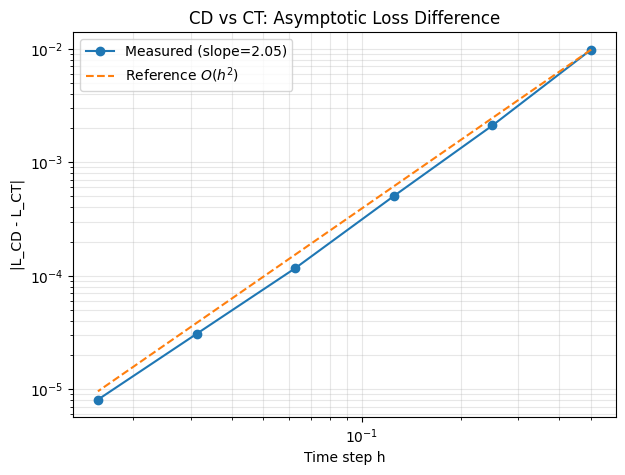

In [9]:
@torch.no_grad()
def experiment_4_asymptotics(gmm):
    print("\n" + "=" * 70)
    print("Experiment 4: CD vs CT Asymptotic Equivalence")
    print("=" * 70)

    # Fixed networks: the theorem compares objectives
    # evaluated at the same parameters.
    online = build_model()
    target = build_model()

    online.eval()
    target.eval()

    # Use fixed time t and different step sizes h.
    t = 5.0

    h_values = [
        0.5,
        0.25,
        0.125,
        0.0625,
        0.03125,
        0.015625,
    ]

    num_samples = 100000
    batch_size = 2000

    results = []

    for h in h_values:

        sum_cd = 0.0
        sum_ct = 0.0
        total = 0

        while total < num_samples:

            b = min(
                batch_size,
                num_samples - total,
            )

            x0 = gmm.sample_data(b)
            z = torch.randn_like(x0)

            x_t = x0 + t * z

            t_high = torch.full(
                (b, 1),
                t,
                device=DEVICE,
            )

            t_low = torch.full(
                (b, 1),
                t - h,
                device=DEVICE,
            )

            # CT random conditional path.
            x_ct = x_t - h * z

            # CD Euler step with exact marginal velocity.
            velocity = gmm.exact_velocity(
                x_t,
                t_high,
            )

            x_cd = x_t - h * velocity

            pred = online(x_t, t_high)

            target_cd = target(x_cd, t_low)
            target_ct = target(x_ct, t_low)

            # Per-sample squared L2.
            loss_cd = torch.sum(
                (pred - target_cd)**2,
                dim=-1,
            )

            loss_ct = torch.sum(
                (pred - target_ct)**2,
                dim=-1,
            )

            sum_cd += loss_cd.sum().item()
            sum_ct += loss_ct.sum().item()

            total += b

        L_cd = sum_cd / total
        L_ct = sum_ct / total

        difference = abs(L_cd - L_ct)

        results.append(
            {
                "h": h,
                "loss_cd": L_cd,
                "loss_ct": L_ct,
                "difference": difference,
            }
        )

        print(
            f"h={h:.6f} | "
            f"CD={L_cd:.8f} | "
            f"CT={L_ct:.8f} | "
            f"|Diff|={difference:.8f}"
        )

    save_csv(
        results,
        "exp4_asymptotic_loss.csv",
    )

    h_array = np.array(
        [r["h"] for r in results]
    )

    diff_array = np.array(
        [r["difference"] for r in results]
    )

    # Avoid log(0).
    diff_array = np.maximum(diff_array, 1e-14)

    slope, intercept = np.polyfit(
        np.log(h_array),
        np.log(diff_array),
        1,
    )

    print(
        f"\nEstimated log-log slope: {slope:.4f}"
    )

    print(
        "Expected asymptotic slope: approximately 2 "
        "for the smooth squared-L2 local comparison."
    )

    plt.figure(figsize=(7, 5))

    plt.loglog(
        h_array,
        diff_array,
        "o-",
        label=f"Measured (slope={slope:.2f})",
    )

    reference = (
        diff_array[0]
        * (h_array / h_array[0])**2
    )

    plt.loglog(
        h_array,
        reference,
        "--",
        label=r"Reference $O(h^2)$",
    )

    plt.xlabel("Time step h")
    plt.ylabel("|L_CD - L_CT|")
    plt.title("CD vs CT: Asymptotic Loss Difference")
    plt.legend()
    plt.grid(alpha=0.3, which="both")

    save_figure("exp4_asymptotic_loss.png")

experiment_4_asymptotics(gmm)


# 七、实验 5：一步生成与多步生成

## 7.1 实验目的

验证：

$$
\boxed{
\text{Consistency Model 可以一步生成}
}
$$

并研究多次重新加噪是否改善生成质量。

## 7.2 一步生成

采样：

$$
X_T\sim p_T
$$

得到：

$$
\widehat X_\epsilon=f_\theta(X_T,T)
$$

网络评估次数：

$$
\mathrm{NFE}=1
$$

## 7.3 多步生成

首先：

$$
\widehat X_\epsilon^{(1)}
=
f_\theta(X_T,T)
$$

选择：

$$
\tau_1=5
$$

重新加噪：

$$
\widetilde X_{\tau_1}
=
\widehat X_\epsilon^{(1)}
+
\sqrt{\tau_1^2-\epsilon^2}Z
$$

再次预测：

$$
\widehat X_\epsilon^{(2)}
=
f_\theta(\widetilde X_{\tau_1},\tau_1)
$$

可以设计：

| NFE | 中间噪声水平 |
|---|---|
| 1 | 无 |
| 2 | 5 |
| 3 | 5、2 |
| 4 | 5、2、1 |
| 5 | 5、2、1、0.5 |

分别计算：

$$
\operatorname{MMD}(p_\theta,p_\epsilon)
$$

以及八个模态的覆盖率。

## 7.4 预期结果

可能出现：

$$
\mathrm{MMD}_{\mathrm{NFE}=2}
<
\mathrm{MMD}_{\mathrm{NFE}=1}
$$

但不能保证 MMD 随 NFE 单调下降。

这里还需要注意：如果模型已经非常准确，多次重新加噪未必进一步改善结果。

因此建议同时比较 CD 和 CT：

$$
\mathrm{CD\text{-}1step}
$$

$$
\mathrm{CD\text{-}2step}
$$

$$
\mathrm{CT\text{-}1step}
$$

$$
\mathrm{CT\text{-}2step}
$$

这样可以研究：**模型的终点预测误差是否影响多步采样带来的收益。**

---



Experiment 5: One-step vs Multi-step Sampling
Real-vs-real MMD baseline: 0.000667
CD-Heun         | NFE=1 | MMD=0.003054 | Coverage=1.000
CD-Heun         | NFE=2 | MMD=0.001852 | Coverage=1.000
CD-Heun         | NFE=3 | MMD=0.001960 | Coverage=1.000
CD-Heun         | NFE=4 | MMD=0.001310 | Coverage=1.000
CD-Heun         | NFE=5 | MMD=0.001657 | Coverage=1.000
CT-Fixed        | NFE=1 | MMD=0.009318 | Coverage=1.000
CT-Fixed        | NFE=2 | MMD=0.006922 | Coverage=1.000
CT-Fixed        | NFE=3 | MMD=0.004109 | Coverage=1.000
CT-Fixed        | NFE=4 | MMD=0.001744 | Coverage=1.000
CT-Fixed        | NFE=5 | MMD=0.001441 | Coverage=1.000


CT-Schedule     | NFE=1 | MMD=0.013420 | Coverage=1.000
CT-Schedule     | NFE=2 | MMD=0.008341 | Coverage=1.000


CT-Schedule     | NFE=3 | MMD=0.003429 | Coverage=1.000
CT-Schedule     | NFE=4 | MMD=0.001933 | Coverage=1.000
CT-Schedule     | NFE=5 | MMD=0.001460 | Coverage=1.000
exp5_sampling.csv


,model,nfe,mmd,mmd_over_floor,mode_coverage,valid_ratio
0,CD-Heun,1,0.003054,0.002387,1.0,0.837891
1,CD-Heun,2,0.001852,0.001185,1.0,0.883301
2,CD-Heun,3,0.001960,0.001293,1.0,0.910156
3,CD-Heun,4,0.001310,0.000643,1.0,0.947266
4,CD-Heun,5,0.001657,0.000990,1.0,0.981445
5,CT-Fixed,1,0.009318,0.008651,1.0,0.664062
6,CT-Fixed,2,0.006922,0.006255,1.0,0.719238
7,CT-Fixed,3,0.004109,0.003442,1.0,0.791992
8,CT-Fixed,4,0.001744,0.001077,1.0,0.878418
9,CT-Fixed,5,0.001441,0.000774,1.0,0.941406


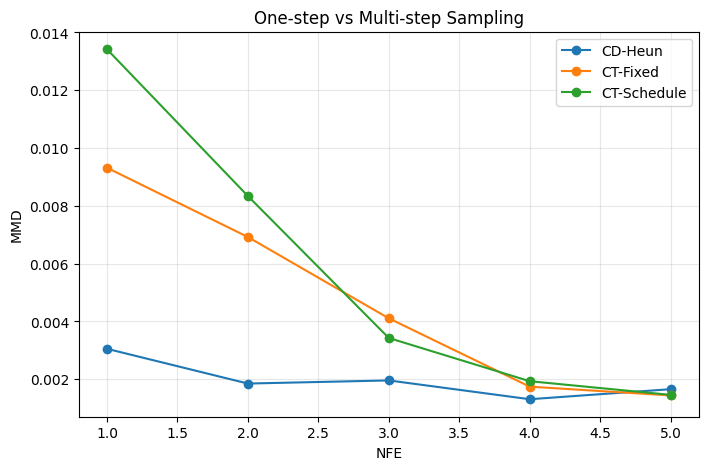

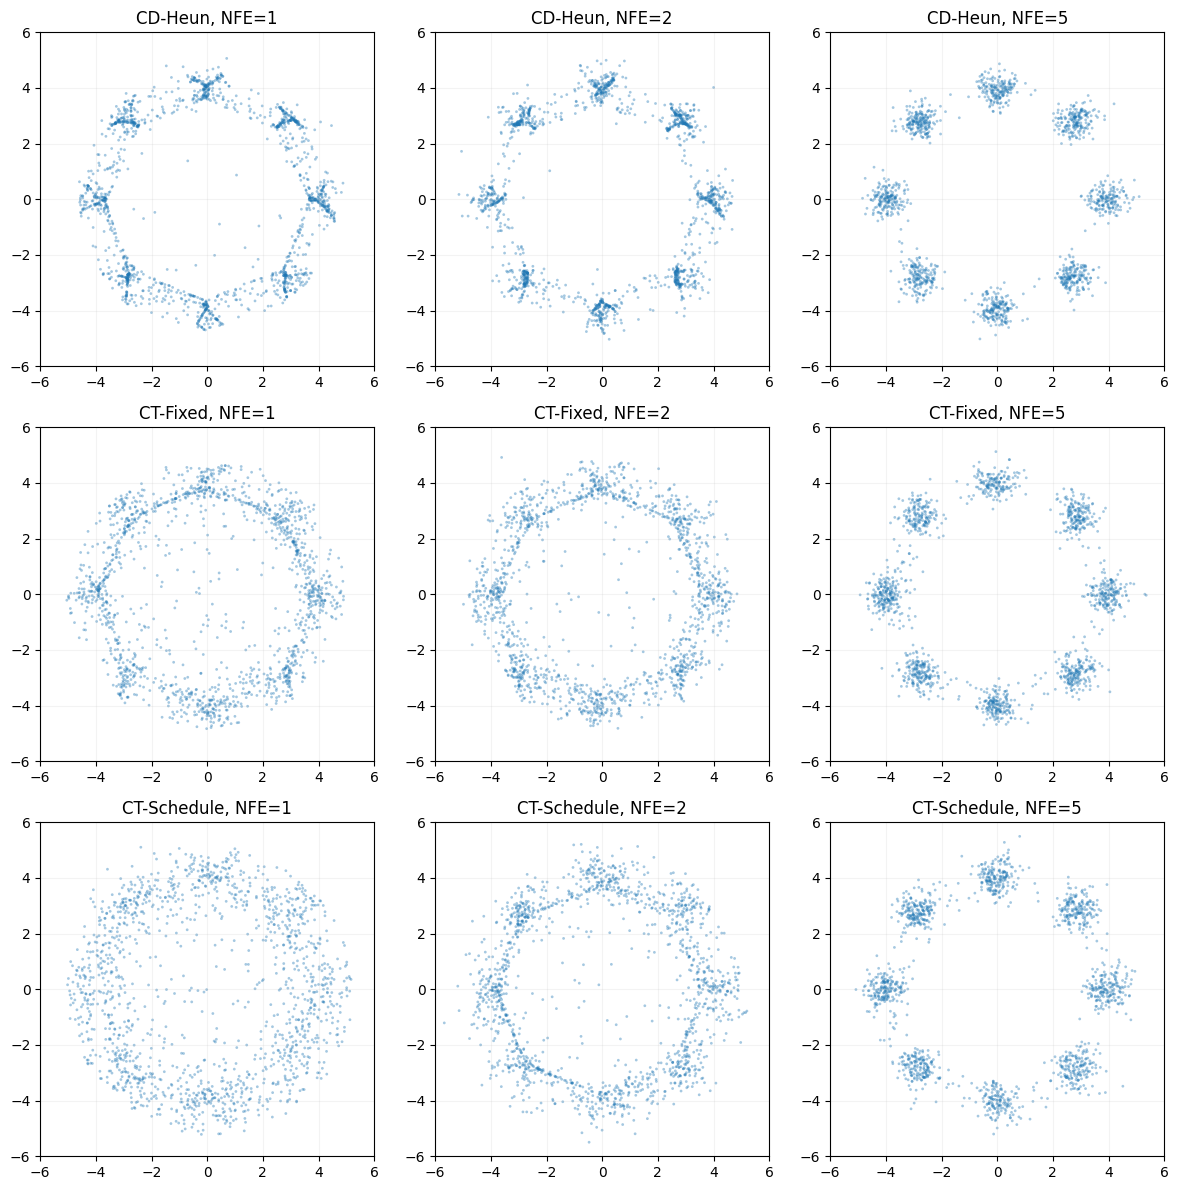

In [10]:
@torch.no_grad()
def experiment_5_sampling(gmm, models):
    print("\n" + "=" * 70)
    print("Experiment 5: One-step vs Multi-step Sampling")
    print("=" * 70)

    schedules = {
        1: [],
        2: [5.0],
        3: [5.0, 2.0],
        4: [5.0, 2.0, 1.0],
        5: [5.0, 2.0, 1.0, 0.5],
    }

    reference = gmm.sample_marginal(
        CFG.eval_samples,
        CFG.eps,
    )

    reference_2 = gmm.sample_marginal(CFG.eval_samples, CFG.eps)
    mmd_floor = compute_mmd(reference, reference_2)
    print(f"Real-vs-real MMD baseline: {mmd_floor:.6f}")

    results = []

    for model_name, model in models.items():

        for nfe, noise_levels in schedules.items():

            generated = sample_multi_step(
                model,
                gmm,
                num_samples=CFG.eval_samples,
                noise_levels=noise_levels,
            )

            mmd = compute_mmd(
                generated,
                reference,
            )

            coverage, _, valid_ratio = mode_coverage(
                generated,
                gmm,
            )

            results.append(
                {
                    "model": model_name,
                    "nfe": nfe,
                    "mmd": mmd,
                    "mmd_over_floor": mmd - mmd_floor,
                    "mode_coverage": coverage,
                    "valid_ratio": valid_ratio,
                }
            )

            print(
                f"{model_name:15s} | "
                f"NFE={nfe} | "
                f"MMD={mmd:.6f} | "
                f"Coverage={coverage:.3f}"
            )

    save_csv(
        results,
        "exp5_sampling.csv",
    )

    df = pd.DataFrame(results)

    plt.figure(figsize=(8, 5))

    for model_name in df["model"].unique():

        subset = df[df["model"] == model_name]

        plt.plot(
            subset["nfe"],
            subset["mmd"],
            marker="o",
            label=model_name,
        )

    plt.xlabel("NFE")
    plt.ylabel("MMD")
    plt.title("One-step vs Multi-step Sampling")
    plt.legend()
    plt.grid(alpha=0.3)

    save_figure("exp5_nfe_vs_mmd.png")


    # Directly inspect whether lower MMD corresponds to recovered modes.
    selected = {1: [], 2: [5.0], 5: [5.0, 2.0, 1.0, 0.5]}
    fig, axes = plt.subplots(len(models), 3, figsize=(12, 4 * len(models)), squeeze=False)
    for row, (model_name, model) in enumerate(models.items()):
        for col, (nfe, levels) in enumerate(selected.items()):
            samples = sample_multi_step(model, gmm, num_samples=1500, noise_levels=levels)
            p = to_numpy(samples)
            axes[row, col].scatter(p[:, 0], p[:, 1], s=4, alpha=0.4, edgecolors="none")
            axes[row, col].set(title=f"{model_name}, NFE={nfe}", xlim=(-6, 6), ylim=(-6, 6))
            axes[row, col].set_aspect("equal")
            axes[row, col].grid(alpha=0.15)
    fig.tight_layout()
    save_figure("exp5_multistep_samples.png")

experiment_5_sampling(gmm, models)


## 附加实验：精确 $p_T$ 与高斯近似先验

VE 前向过程的真实终点是 $p_T=p_{\mathrm{data}}*\mathcal N(0,T^2I)$，并不严格等于 $\mathcal N(0,T^2I)$。下面固定同一批训练模型，只改变生成起点，测量先验失配带来的 MMD。



Additional Experiment: Prior Mismatch
CD-Heun         | Prior=Exact    | MMD=0.003438
CD-Heun         | Prior=Gaussian | MMD=0.002720
CT-Fixed        | Prior=Exact    | MMD=0.008568
CT-Fixed        | Prior=Gaussian | MMD=0.009099
CT-Schedule     | Prior=Exact    | MMD=0.012949
CT-Schedule     | Prior=Gaussian | MMD=0.014696
exp_prior_mismatch.csv


,model,prior,mmd
0,CD-Heun,exact_pT,0.003438
1,CD-Heun,gaussian,0.002720
2,CT-Fixed,exact_pT,0.008568
3,CT-Fixed,gaussian,0.009099
4,CT-Schedule,exact_pT,0.012949
5,CT-Schedule,gaussian,0.014696


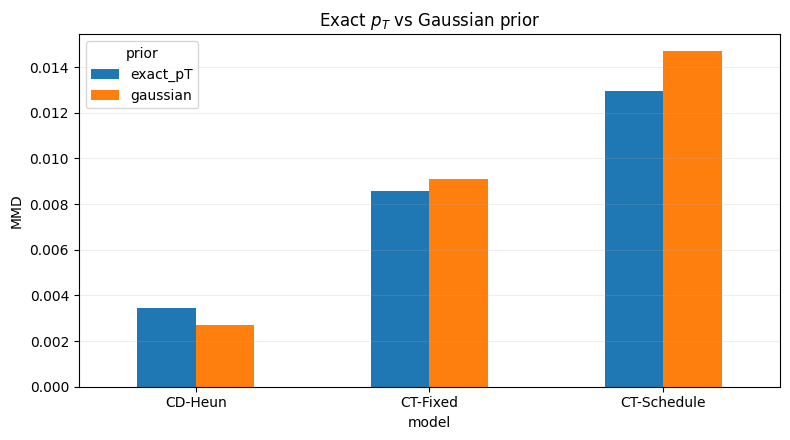

In [11]:
@torch.no_grad()
def experiment_prior_mismatch(gmm, models):
    """
    Compare exact p_T sampling with Gaussian approximation.

    Exact:
        X_T ~ p_T

    Approximate:
        X_T ~ N(0,T^2 I)
    """
    print("\n" + "=" * 70)
    print("Additional Experiment: Prior Mismatch")
    print("=" * 70)

    reference = gmm.sample_marginal(
        CFG.eval_samples,
        CFG.eps,
    )

    results = []

    for name, model in models.items():

        for exact_prior in [True, False]:

            samples = sample_one_step(
                model,
                gmm,
                num_samples=CFG.eval_samples,
                exact_prior=exact_prior,
            )

            mmd = compute_mmd(
                samples,
                reference,
            )

            results.append(
                {
                    "model": name,
                    "prior": (
                        "exact_pT"
                        if exact_prior
                        else "gaussian"
                    ),
                    "mmd": mmd,
                }
            )

            print(
                f"{name:15s} | "
                f"Prior={'Exact' if exact_prior else 'Gaussian':8s} | "
                f"MMD={mmd:.6f}"
            )

    save_csv(
        results,
        "exp_prior_mismatch.csv",
    )


    df = pd.DataFrame(results)
    pivot = df.pivot(index="model", columns="prior", values="mmd")
    pivot.plot(kind="bar", figsize=(8, 4.5))
    plt.ylabel("MMD")
    plt.title("Exact $p_T$ vs Gaussian prior")
    plt.xticks(rotation=0)
    plt.grid(alpha=0.2, axis="y")
    plt.tight_layout()
    save_figure("exp_prior_mismatch.png")

experiment_prior_mismatch(gmm, models)


# 八、实验 6：验证教师 ODE Solver 的误差阶

## 8.1 实验目的

验证论文 Theorem 1 背后的数值分析结论：

$$
\boxed{
E=O((\Delta t)^p)
}
\tag{19}
$$

其中：

$$
p
$$

是 Solver 的阶数。

不过，为了避免神经网络训练误差掩盖 Solver 的误差，建议分成两个子实验。

## 8.2 实验 6A：只比较 Solver，不训练网络

首先使用高精度 RK4 得到参考终点：

$$
X_{\epsilon,\mathrm{GT}}
$$

然后分别使用 Euler 和 Heun 积分：

$$
T\rightarrow\epsilon
$$

设积分步数：

$$
N\in\{10,20,40,80,160\}
$$

计算：

$$
E_{\mathrm{Euler}}(N)
=
\mathbb E
\|X_{\epsilon,\mathrm{Euler}}-X_{\epsilon,\mathrm{GT}}\|
\tag{20}
$$

$$
E_{\mathrm{Heun}}(N)
=
\mathbb E
\|X_{\epsilon,\mathrm{Heun}}-X_{\epsilon,\mathrm{GT}}\|
\tag{21}
$$

注意这里使用的是**非平方误差**。

预期：

$$
E_{\mathrm{Euler}}=O(h)
$$

$$
E_{\mathrm{Heun}}=O(h^2)
$$

因此 Log-Log 曲线：

- Euler 斜率约为 1。
- Heun 斜率约为 2。

如果使用 MSE，则预期斜率相应变为 2 和 4。

## 8.3 实验 6B：比较不同教师 Solver 训练出的 CM

训练：

$$
\mathrm{CD\text{-}Euler}
$$

和：

$$
\mathrm{CD\text{-}Heun}
$$

保证：

- 相同网络结构。
- 相同数据。
- 相同训练步数。
- 相同时间网格。
- 相同优化器。
- 相同 EMA。

比较终点误差：

$$
E_{\mathrm{endpoint}}
$$

理论上，高阶教师能够提供更准确的局部轨迹监督。

但需要注意：

**Theorem 1 的 $O(h^p)$ 是理想化条件下的误差界，并不保证有限容量、有限训练步数的神经网络也呈现严格的 $p$ 阶收敛。**

因此：

实验 6A 验证数值 Solver 的阶数。

实验 6B 验证高阶教师对实际 CM 训练是否有帮助。

两者不能混为一谈。

---



Experiment 6: Euler vs Heun Convergence


euler  | N= 10 | h=0.999000 | Error=0.37534523
heun   | N= 10 | h=0.999000 | Error=0.37300986
euler  | N= 20 | h=0.499500 | Error=0.14851892
heun   | N= 20 | h=0.499500 | Error=0.09230722
euler  | N= 40 | h=0.249750 | Error=0.07433257
heun   | N= 40 | h=0.249750 | Error=0.02578932
euler  | N= 80 | h=0.124875 | Error=0.03848541
heun   | N= 80 | h=0.124875 | Error=0.00754036
euler  | N=160 | h=0.062437 | Error=0.01976977
heun   | N=160 | h=0.062437 | Error=0.00206239
euler  | N=320 | h=0.031219 | Error=0.01004643
heun   | N=320 | h=0.031219 | Error=0.00053936
exp6_solver_order.csv


,method,num_steps,h,endpoint_error
0,euler,10,0.999000,0.375345
1,heun,10,0.999000,0.373010
2,euler,20,0.499500,0.148519
3,heun,20,0.499500,0.092307
4,euler,40,0.249750,0.074333
5,heun,40,0.249750,0.025789
6,euler,80,0.124875,0.038485
7,heun,80,0.124875,0.007540
8,euler,160,0.062437,0.019770
9,heun,160,0.062437,0.002062


Estimated euler order: 0.9623
Estimated heun order: 1.8608


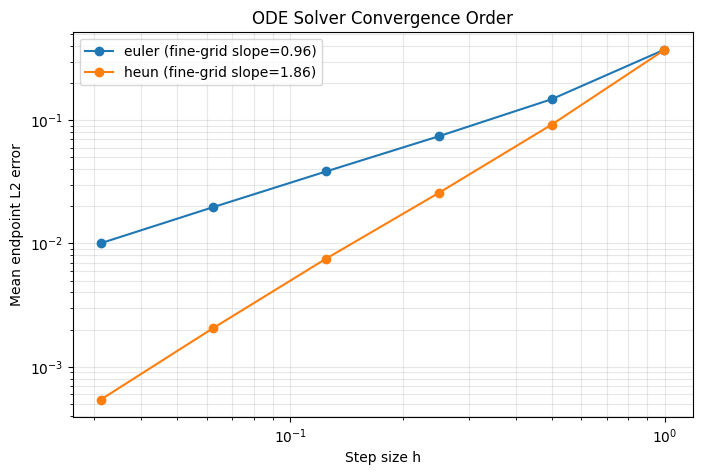

In [12]:
@torch.no_grad()
def experiment_6_solver_order(gmm):
    print("\n" + "=" * 70)
    print("Experiment 6: Euler vs Heun Convergence")
    print("=" * 70)

    x_T = gmm.sample_marginal(
        2048,
        CFG.T,
    )

    # High-accuracy numerical reference.
    reference = integrate_ode(
        x_T,
        CFG.T,
        CFG.eps,
        gmm.exact_velocity,
        num_steps=4000,
        method="rk4",
    )

    step_counts = [
        10,
        20,
        40,
        80,
        160,
        320,
    ]

    results = []

    for num_steps in step_counts:

        h = (CFG.T - CFG.eps) / num_steps

        for method in ["euler", "heun"]:

            prediction = integrate_ode(
                x_T,
                CFG.T,
                CFG.eps,
                gmm.exact_velocity,
                num_steps=num_steps,
                method=method,
            )

            # Mean Euclidean endpoint error,
            # not squared MSE.
            error = torch.norm(
                prediction - reference,
                dim=-1,
            ).mean().item()

            results.append(
                {
                    "method": method,
                    "num_steps": num_steps,
                    "h": h,
                    "endpoint_error": error,
                }
            )

            print(
                f"{method:6s} | "
                f"N={num_steps:3d} | "
                f"h={h:.6f} | "
                f"Error={error:.8f}"
            )

    save_csv(
        results,
        "exp6_solver_order.csv",
    )

    df = pd.DataFrame(results)

    plt.figure(figsize=(8, 5))

    for method in ["euler", "heun"]:

        subset = df[df["method"] == method]

        h = subset["h"].to_numpy()
        error = subset["endpoint_error"].to_numpy()

        fine = np.argsort(h)[:4]
        slope, _ = np.polyfit(
            np.log(h[fine]),
            np.log(np.maximum(error[fine], 1e-14)),
            1,
        )

        plt.loglog(
            h,
            error,
            "o-",
            label=f"{method} (fine-grid slope={slope:.2f})",
        )

        print(
            f"Estimated {method} order: {slope:.4f}"
        )

    plt.xlabel("Step size h")
    plt.ylabel("Mean endpoint L2 error")
    plt.title("ODE Solver Convergence Order")
    plt.legend()
    plt.grid(alpha=0.3, which="both")

    save_figure("exp6_solver_convergence.png")

experiment_6_solver_order(gmm)


# 九、建议增加两个消融实验

这两个实验不需要额外设计复杂框架，但能够帮助理解论文的重要细节。

## 9.1 消融 A：EMA 是否必要？

比较：

$$
\mu=0
$$

$$
\mu=0.9
$$

$$
\mu=0.99
$$

$$
\mu=0.999
$$

观察：

- 训练 Loss。
- Endpoint MSE。
- 生成 MMD。
- 梯度范数。

注意 EMA 越大，Target 更新越慢，并不意味着一定越好。

## 9.2 消融 B：边界条件是否必要？

比较：

**模型 A：具有边界约束**

$$
f_\theta(x,\epsilon)=x
$$

**模型 B：普通 MLP，无边界约束**

$$
f_\theta(x,t)=F_\theta(x,t)
$$

如果只使用一致性 Loss，模型 B 可能学习到退化映射，例如：

$$
f_\theta(x,t)\approx c
$$

因为常数函数同样满足相邻时间输出一致。

因此可以观察：

$$
E_{\mathrm{boundary}}
=
\mathbb E
\|f_\theta(X_\epsilon,\epsilon)-X_\epsilon\|^2
\tag{22}
$$

以及生成分布是否坍缩。

这个实验能够直观解释：

**为什么一致性条件本身不足以确定正确的终点映射。**

---



Experiment 7: Ablation Studies

Running ablation: CT-EMA-0


CT-EMA-0: Endpoint MSE=1.389173, MMD=0.026816, Boundary MSE=0.000000

Running ablation: CT-EMA-0.9


CT-EMA-0.9: Endpoint MSE=0.316854, MMD=0.011160, Boundary MSE=0.000000

Running ablation: CT-EMA-0.99


CT-EMA-0.99: Endpoint MSE=1.796393, MMD=0.063456, Boundary MSE=0.000000

Running ablation: CT-IndependentNoise


CT-IndependentNoise: Endpoint MSE=14.202317, MMD=0.795300, Boundary MSE=0.000000

Running ablation: CT-NoBoundary


CT-NoBoundary: Endpoint MSE=16.122861, MMD=0.876479, Boundary MSE=8.200212

Running ablation: CD-Euler


CD-Euler: Endpoint MSE=0.916905, MMD=0.041465, Boundary MSE=0.000000

Running ablation: CD-Heun


CD-Heun: Endpoint MSE=0.901425, MMD=0.040429, Boundary MSE=0.000000
exp7_ablations.csv


,experiment,endpoint_mse,mmd,boundary_mse,final_training_loss
0,CT-EMA-0,1.389173,0.026816,0.000000,2.638371e-04
1,CT-EMA-0.9,0.316854,0.011160,0.000000,1.143020e-04
2,CT-EMA-0.99,1.796393,0.063456,0.000000,6.078312e-05
3,CT-IndependentNoise,14.202317,0.795300,0.000000,9.325871e-03
4,CT-NoBoundary,16.122861,0.876479,8.200212,5.425387e-08
5,CD-Euler,0.916905,0.041465,0.000000,5.277253e-05
6,CD-Heun,0.901425,0.040429,0.000000,4.132421e-05


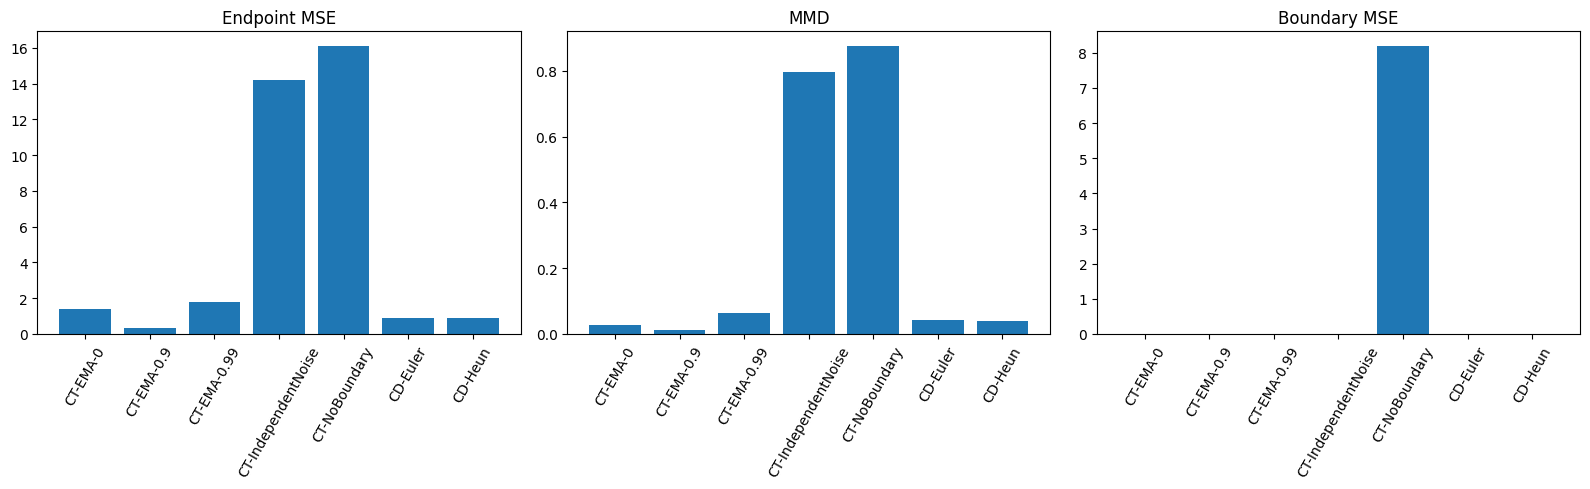

In [13]:
def experiment_7_ablations(gmm):
    print("\n" + "=" * 70)
    print("Experiment 7: Ablation Studies")
    print("=" * 70)

    experiments = [
        {
            "name": "CT-EMA-0",
            "method": "ct",
            "ema_decay": 0.0,
            "use_schedule": True,
            "shared_noise": True,
            "use_boundary": True,
        },
        {
            "name": "CT-EMA-0.9",
            "method": "ct",
            "ema_decay": 0.9,
            "use_schedule": True,
            "shared_noise": True,
            "use_boundary": True,
        },
        {
            "name": "CT-EMA-0.99",
            "method": "ct",
            "ema_decay": 0.99,
            "use_schedule": True,
            "shared_noise": True,
            "use_boundary": True,
        },
        {
            "name": "CT-IndependentNoise",
            "method": "ct",
            "ema_decay": 0.99,
            "use_schedule": True,
            "shared_noise": False,
            "use_boundary": True,
        },
        {
            "name": "CT-NoBoundary",
            "method": "ct",
            "ema_decay": 0.99,
            "use_schedule": True,
            "shared_noise": True,
            "use_boundary": False,
        },
        {
            "name": "CD-Euler",
            "method": "cd",
            "ema_decay": 0.99,
            "use_schedule": False,
            "shared_noise": True,
            "use_boundary": True,
            "teacher_solver": "euler",
        },
        {
            "name": "CD-Heun",
            "method": "cd",
            "ema_decay": 0.99,
            "use_schedule": False,
            "shared_noise": True,
            "use_boundary": True,
            "teacher_solver": "heun",
        },
    ]

    results = []

    reference = gmm.sample_marginal(
        CFG.eval_samples,
        CFG.eps,
    )

    for exp in experiments:

        name = exp["name"]

        print(f"\nRunning ablation: {name}")

        kwargs = {
            k: v
            for k, v in exp.items()
            if k != "name"
        }

        model, ema_model, history = train_consistency_model(
            gmm,
            train_steps=CFG.ablation_steps,
            verbose=False,
            **kwargs,
        )

        error = endpoint_mse(
            ema_model,
            gmm,
            num_samples=1024,
            reference_steps=500,
        )

        generated = sample_one_step(
            ema_model,
            gmm,
            num_samples=CFG.eval_samples,
        )

        mmd = compute_mmd(
            generated,
            reference,
        )

        # Boundary error.
        x_eps = gmm.sample_marginal(
            1024,
            CFG.eps,
        )

        with torch.no_grad():
            pred_eps = ema_model(
                x_eps,
                CFG.eps,
            )

            boundary_error = F.mse_loss(
                pred_eps,
                x_eps,
            ).item()

        results.append(
            {
                "experiment": name,
                "endpoint_mse": error,
                "mmd": mmd,
                "boundary_mse": boundary_error,
                "final_training_loss": history["loss"][-1],
            }
        )

        print(
            f"{name}: "
            f"Endpoint MSE={error:.6f}, "
            f"MMD={mmd:.6f}, "
            f"Boundary MSE={boundary_error:.6f}"
        )

    save_csv(
        results,
        "exp7_ablations.csv",
    )

    df = pd.DataFrame(results)

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(16, 5),
    )

    names = df["experiment"].tolist()

    axes[0].bar(
        names,
        df["endpoint_mse"],
    )
    axes[0].set_title("Endpoint MSE")
    axes[0].tick_params(axis="x", rotation=60)

    axes[1].bar(
        names,
        df["mmd"],
    )
    axes[1].set_title("MMD")
    axes[1].tick_params(axis="x", rotation=60)

    axes[2].bar(
        names,
        df["boundary_mse"],
    )
    axes[2].set_title("Boundary MSE")
    axes[2].tick_params(axis="x", rotation=60)

    plt.tight_layout()

    save_figure("exp7_ablations.png")


if CFG.run_ablations:
    experiment_7_ablations(gmm)
else:
    print("消融实验默认关闭；设置 CFG.run_ablations=True 后重新运行本单元即可启用。")


# 十、代码架构设计

建议使用一个 Jupyter Notebook，所有代码按模块组织，不需要建立复杂项目。

```text
Consistency Models Experiments
│
├── 1. 环境配置与随机种子
│
├── 2. GMM 数据分布
│   ├── sample_data()
│   ├── sample_noisy()
│   ├── exact_score()
│   └── exact_velocity()
│
├── 3. ODE Solver
│   ├── euler_step()
│   ├── heun_step()
│   └── rk4_integrate()
│
├── 4. Consistency Model
│   ├── TimeEmbedding
│   ├── ConsistencyMLP
│   └── EMA
│
├── 5. Training
│   ├── train_cd()
│   └── train_ct()
│
├── 6. Evaluation
│   ├── endpoint_mse()
│   ├── consistency_error()
│   ├── compute_mmd()
│   └── mode_coverage()
│
├── 7. Sampling
│   ├── sample_one_step()
│   └── sample_multi_step()
│
└── 8. Experiments
    ├── Experiment 1: PF ODE Consistency
    ├── Experiment 2: CD Training
    ├── Experiment 3: CT Training
    ├── Experiment 4: CD vs CT Asymptotics
    ├── Experiment 5: One-step vs Multi-step
    └── Experiment 6: Euler vs Heun
```

---

# 十一、实验中的三个关键注意事项

### 1. 初始分布要与目标 PF ODE 匹配

本实验选择：

$$
X_t=X_0+tZ
$$

因此：

$$
p_T
=
p_{\mathrm{data}}*\mathcal N(0,T^2I)
$$

它并不严格等于：

$$
\mathcal N(0,T^2I)
$$

为了准确验证理论，建议先从真实 $p_T$ 采样。

然后增加一个额外对照：

$$
X_T\sim\mathcal N(0,T^2I)
$$

研究近似高斯先验带来的误差。

这样能够区分：

- 一致性模型自身的学习误差。
- 初始分布不匹配带来的生成误差。

### 2. 不要只比较 Training Loss

对于 CD 和 CT：

$$
\mathcal L_{\mathrm{CD}}
$$

与：

$$
\mathcal L_{\mathrm{CT}}
$$

使用不同的状态构造方式。

所以不能仅凭哪个 Loss 更低就判断哪个模型更好。

必须在同一测试集上比较：

$$
E_{\mathrm{endpoint}}
$$

以及：

$$
\operatorname{MMD}
$$

### 3. 每组实验至少重复三个随机种子

建议：

$$
\mathrm{seed}\in\{0,1,2\}
$$

报告：

$$
\text{Mean}\pm\text{Std}
$$

尤其是 CT 的训练稳定性实验，单次运行的结果可能具有偶然性。

---

# 十二、最终实验报告应该包含哪些图？

我建议最后输出以下八张图。

| 图 | 内容 | 验证目标 |
|---|---|---|
| Figure 1 | GMM 数据分布与 PF ODE 轨迹 | 概率流的直观结构 |
| Figure 2 | ODE 轨迹上的终点一致性误差 | Self-Consistency |
| Figure 3 | CD 与 CT 的 Endpoint MSE 曲线 | 两种训练方式的效果 |
| Figure 4 | CD、CT、真实数据的二维散点图 | 一步生成能力 |
| Figure 5 | CD 与 CT Loss 差值的 Log-Log 曲线 | 渐近关系 |
| Figure 6 | 不同 NFE 下的 MMD | 一步与多步采样 |
| Figure 7 | Euler、Heun 的 Log-Log 误差曲线 | Solver 收敛阶 |
| Figure 8 | EMA、时间调度、边界条件消融 | 关键训练机制 |

## 最终推荐的实验顺序

优先完成：

$$
\boxed{
\text{实验 1}
\rightarrow
\text{实验 4}
\rightarrow
\text{实验 6A}
}
$$

这三组不需要训练神经网络，可以先验证理论和数值实现是否正确。

然后完成：

$$
\boxed{
\text{实验 2}
\rightarrow
\text{实验 3}
\rightarrow
\text{实验 5}
}
$$

训练 CD、CT，并比较一步与多步生成。

最后进行：

$$
\boxed{
\text{EMA、时间调度、边界条件消融}
}
$$

**我的建议是先实现这套二维实验的完整 PyTorch 代码，采用 Jupyter 可以直接逐个 Cell 运行的形式。** 其中重点保留真实解析 Score、高精度 ODE 终点、CD/CT 训练以及渐近误差实验，这样每个实验都能直接对应论文中的一个数学结论，而不是仅仅展示生成样本。

# 十三、实际运行结果与逐项分析

下面汇总本次 CUDA、单随机种子、10,000-step 核心训练的实际结果。真实样本与另一批真实样本之间的经验 MMD 约为 `0.00069`，可视为当前样本量和核设置下的参考底噪，而不是严格的零点。

## 13.1 数据分布与解析 PF ODE

- $t=0$ 的八个模态清晰分离，$t=1$ 形成带多峰痕迹的环，$t=10$ 接近宽高斯云，说明 VE 边缘采样与解析分布一致。
- PF ODE 能把高噪声样本输运回八个数据模态。
- 从不同中间时刻重新积分得到的终点 MSE 均在约 $10^{-8}$ 以下，误差已经接近单精度数值积分极限。

因此，解析 Score、速度场和 RK4 教师可以作为后续实验的可靠 Ground Truth。

## 13.2 CD 与 CT 的一步生成

| 模型 | 随机时刻 Endpoint MSE | $t=T$ Endpoint MSE | 一步 MMD | 有效样本比例 | 模态覆盖 |
|---|---:|---:|---:|---:|---:|
| CD-Heun | 0.0738 | 0.1283 | 0.0022 | 0.862 | 1.000 |
| CT-Fixed | 0.2419 | 0.3259 | 0.0092 | 0.673 | 1.000 |
| CT-Schedule | 0.2851 | 0.5079 | 0.0131 | 0.543 | 1.000 |

CD-Heun 的一步结果最好，八个模态已经清晰可见，但模态之间仍残留少量桥接样本。CT 能覆盖全部模态，但分布更宽。当前预算下 CT-Schedule 没有优于 CT-Fixed，说明“逐渐增加时间层数”本身并不保证更好，还需要联合调节 EMA、训练预算和网格调度。

这里也验证了为什么不能只看训练 loss：CT-Schedule 的后期局部一致性 loss 很小，但一步 Endpoint MSE 和 MMD 仍高于另外两种方法。

## 13.3 预条件化与时间网格优化是否有效

逐步修正后的 CD 一步结果为：

| 设置 | 一步 MMD | 有效样本比例 |
|---|---:|---:|
| 原始设置：用 0.3 作为全局数据尺度 | 约 0.104 | 约 0.015 |
| 修正总体尺度并增加输入归一化 | 约 0.019 | 约 0.403 |
| 再加入 Karras 网格与间隔加权 | 约 0.0022 | 约 0.862 |

主要问题来自两个尺度被混淆：`0.3` 是单个高斯模态的宽度，而整个环形数据每个坐标的标准差约为 `2.84`。第二项改进来自 $
ho=7$ 的非均匀时间网格和 $1/(t_{n+1}-t_n)$ 相对权重，它们让低噪声区域获得更充分的分辨率。

## 13.4 CD 与 CT 的局部渐近关系

实测 log-log 斜率为 `2.0467`，非常接近局部平方损失分析预期的 2：

$$
|L_{\mathrm{CD}}(h)-L_{\mathrm{CT}}(h)|=O(h^2).
$$

这项结果支持的是固定网络、固定时间附近的局部数值关系，不应被扩大解释为有限训练下 CD 与 CT 必然达到相同生成质量。

## 13.5 一步与多步采样

| 模型 | NFE=1 MMD | NFE=5 MMD | 最佳观测 MMD |
|---|---:|---:|---:|
| CD-Heun | 0.0031 | 0.0017 | 0.0013（NFE=4） |
| CT-Fixed | 0.0093 | 0.0014 | 0.0014（NFE=5） |
| CT-Schedule | 0.0134 | 0.0015 | 0.0015（NFE=5） |

多步重新加噪明显改善三种模型，并在 NFE=5 时恢复清晰八模态。不过 CD 在 NFE=4 后略有反弹，说明更多 NFE 不保证 MMD 严格单调改善。新增的 NFE=1/2/5 样本图也确认 MMD 的下降确实对应模态逐渐变清晰，而不是单纯的核指标变化。

## 13.6 精确先验与高斯近似先验

精确 $p_T$ 与近似高斯先验的差异总体小于模型误差。CD 中高斯近似本次甚至略低，但差异与有限样本 MMD 波动同量级；CT-Schedule 中精确先验更好。这里不应根据单随机种子断言某种先验总是更优，应至少重复三个种子。

## 13.7 Euler 与 Heun 的收敛阶

使用四个最细网格拟合得到：

- Euler：`0.9623`，接近理论一阶；
- Heun：`1.8608`，接近理论二阶。

Heun 未精确达到 2，主要原因是参考解、单精度浮点和有限步长仍带来误差；但其误差下降速度显著快于 Euler，核心结论成立。

## 13.8 消融实验

| 设置 | Endpoint MSE | MMD | Boundary MSE |
|---|---:|---:|---:|
| CT-EMA-0 | 1.389 | 0.0268 | 0 |
| CT-EMA-0.9 | **0.317** | **0.0112** | 0 |
| CT-EMA-0.99 | 1.796 | 0.0635 | 0 |
| CT-IndependentNoise | 14.202 | 0.7953 | 0 |
| CT-NoBoundary | 16.123 | 0.8765 | 8.200 |
| CD-Euler | 0.917 | 0.0415 | 0 |
| CD-Heun | 0.901 | 0.0404 | 0 |

结论非常清楚：

- 独立噪声破坏了相邻状态的路径耦合，训练几乎失效；
- 没有边界约束时出现退化映射，Boundary MSE 和生成误差同时爆炸；
- EMA 不是越大越好。仅训练 4000 steps 时，`0.99` 的目标更新过慢，`0.9` 更合适；
- Euler 与 Heun 教师差异较小，因为当前相邻 Karras 网格已经较细，神经网络训练误差高于两者的局部积分差异。

## 13.9 仍然存在的限制

1. 当前结果只使用一个随机种子，模型排序需要通过至少三个种子的均值和标准差确认。
2. CT 的一步结果仍弱于 CD，可以继续联合搜索 EMA 调度、训练步数和网络容量。
3. MMD 是核与带宽相关指标，应结合 Endpoint MSE、有效样本比例和直接样本图共同判断。
4. 消融只训练 4000 steps，主要用于方向性判断，不能代替等计算预算的正式比较。
